# 3. Exploratory Data Analysis

## Load Required Libraries and Dataset

In [12]:
#Load required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import skew
from scipy.stats import pointbiserialr

In [13]:
#Load dataset
df = pd.read_csv('../Data/clean_df.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,2
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


## Analysis of Numerical Features

### Summary Statistics

In [14]:
#Summary statistics
df[['age', 'trestbps', 'chol', 'thalach', 'oldpeak']].describe()

,age,trestbps,chol,thalach,oldpeak
count,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,131.693603,247.350168,149.599327,1.055556
std,9.049736,17.762806,51.997583,22.941562,1.166123
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.000000,0.000000
50%,56.000000,130.000000,243.000000,153.000000,0.800000
75%,61.000000,140.000000,276.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


### Distributions

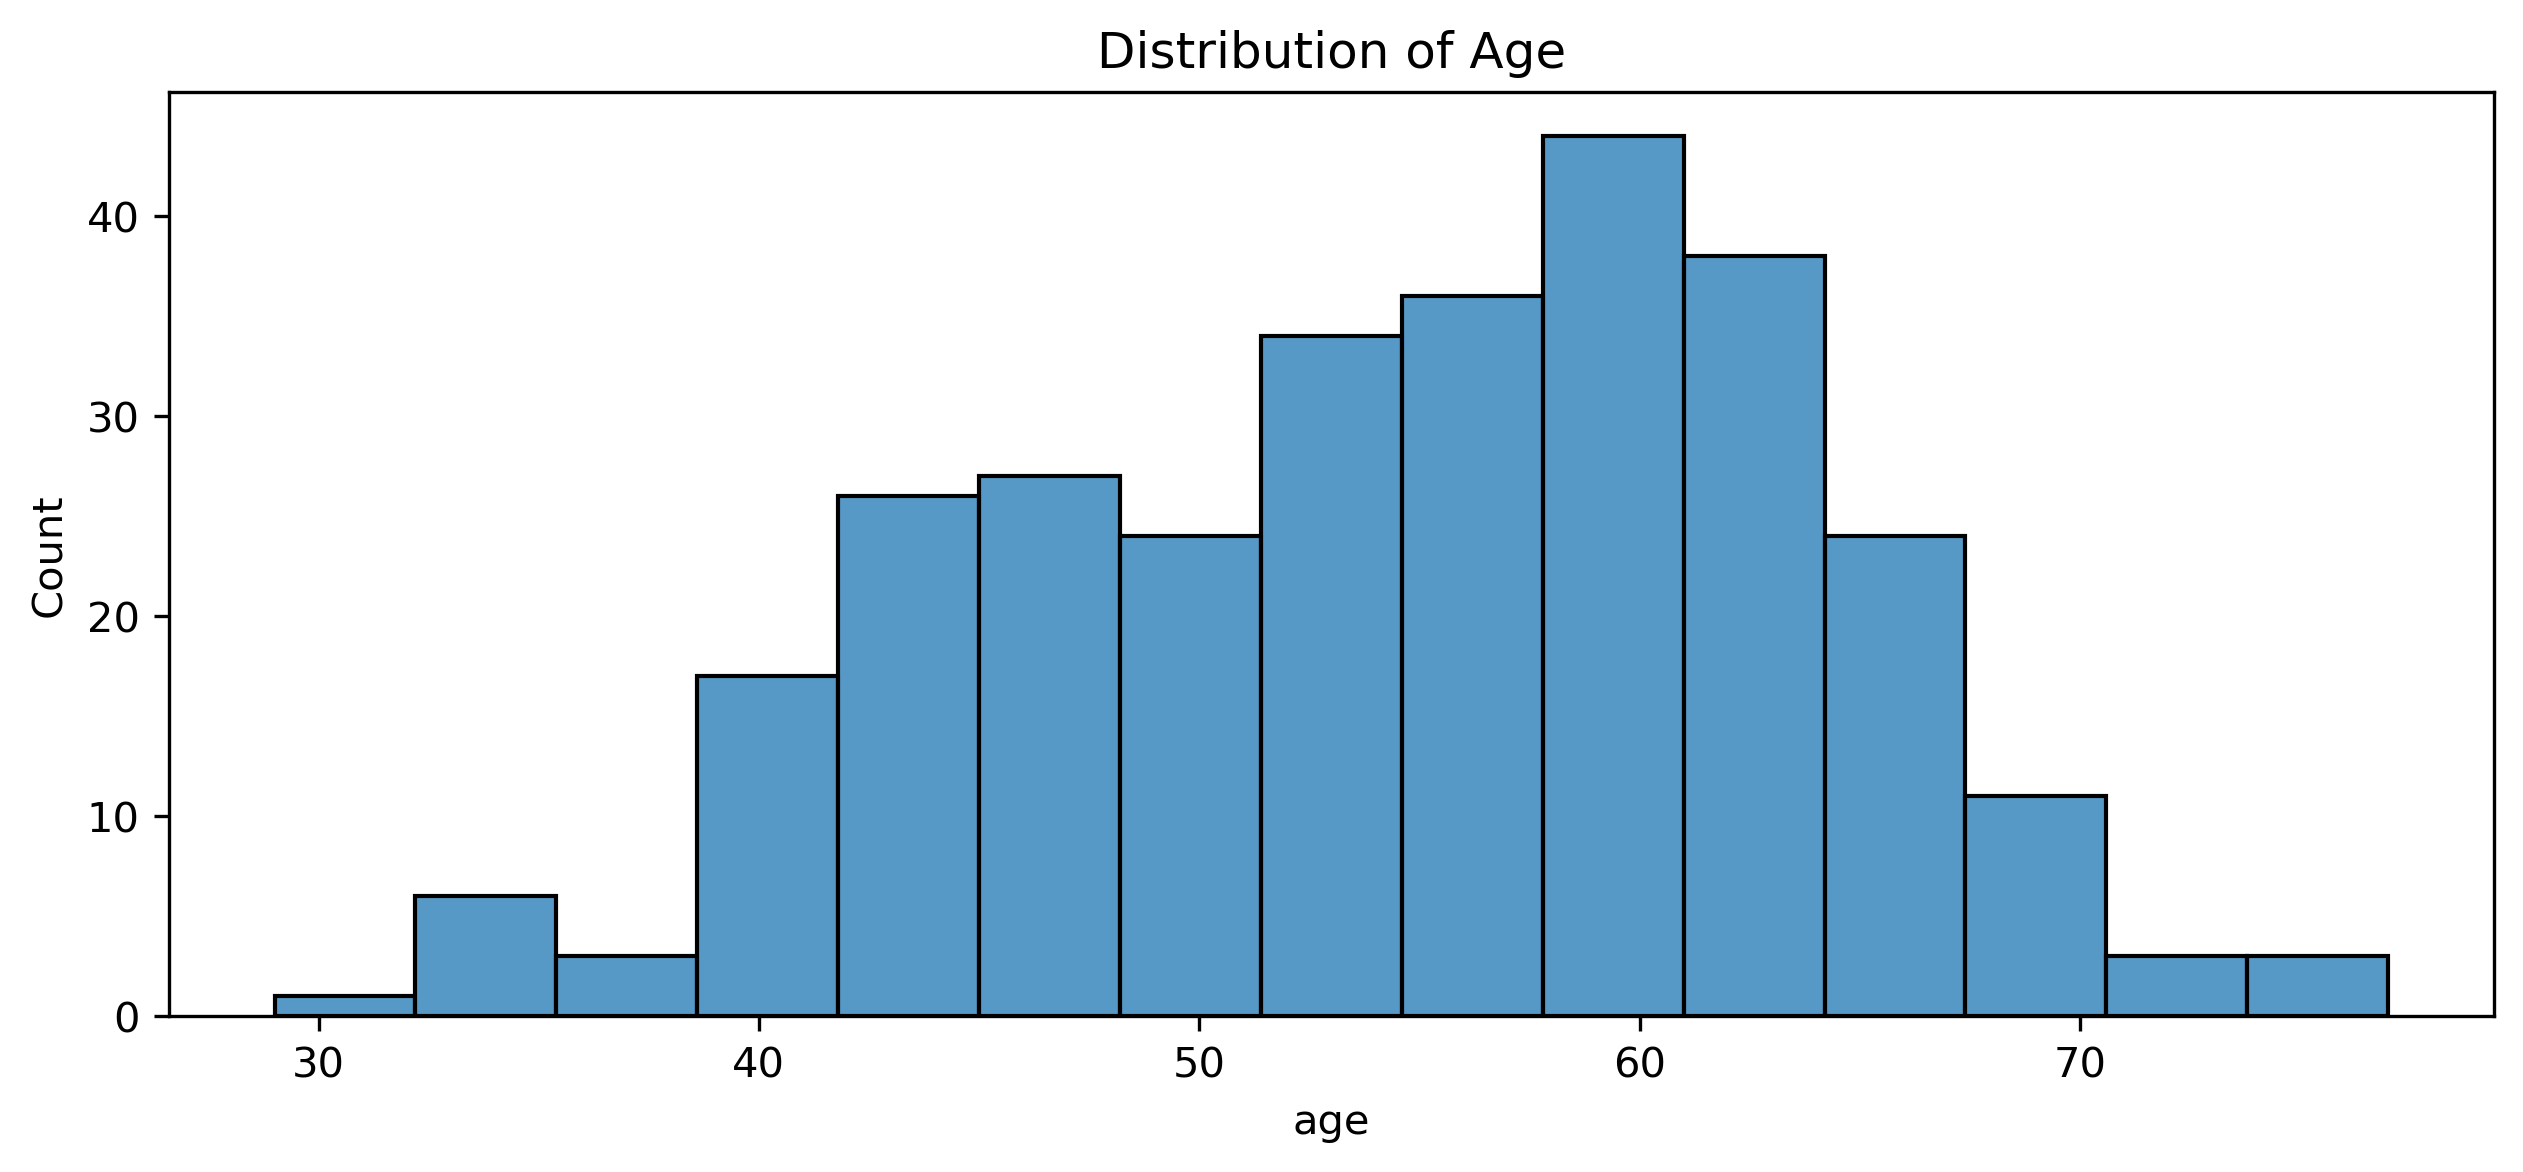

In [15]:
##Age distribution

#Plot histogram
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'age', bins = 15)

plt.title('Distribution of Age')
plt.show()

In [16]:
#Check skew of data
#Check for skew
print(f'Age skew: {df['age'].skew()}')

Age skew: -0.21977452171636244


**Comments:**
* The age of patients in this dataset is concentrated beyween 50 - 65 years old, which is to be expected.
* There are a small number patients who form the youngest of the dataset (under 35 years old) and a small number who form the oldest of the dataset (above 70 years old).
* The age distribution is slightly left skewed as the skewness coefficient is negative. This suggests that a few younger ages pull the tail left, while most patients are older.

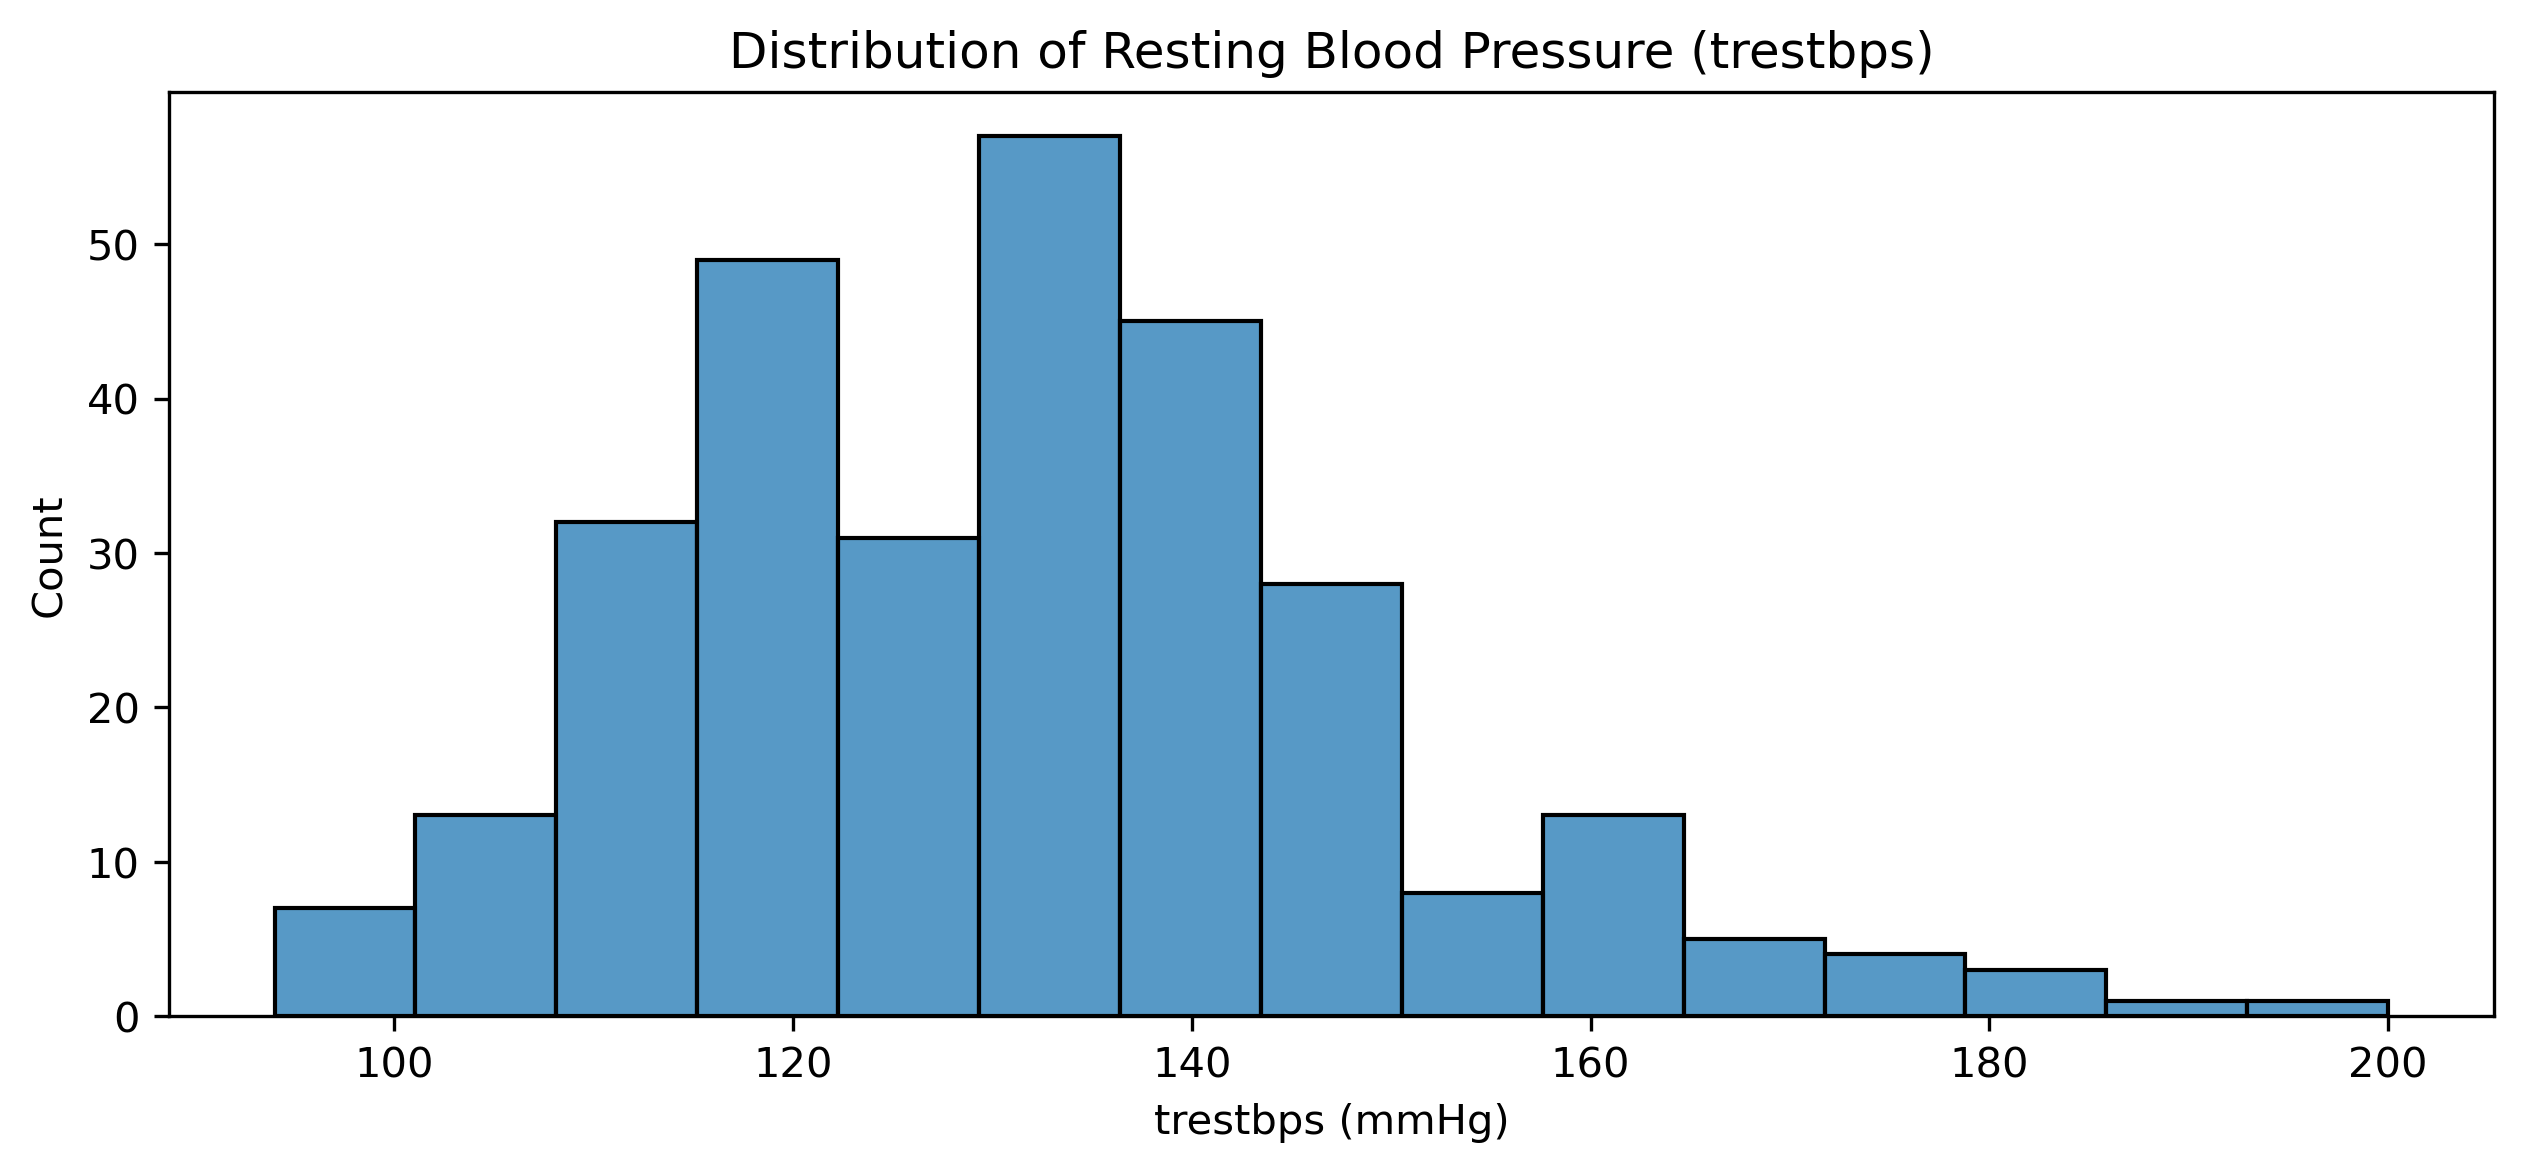

In [17]:
#Distribution of trestbps (resting blood pressure)

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'trestbps', bins = 15)

plt.title('Distribution of Resting Blood Pressure (trestbps)')
plt.xlabel('trestbps (mmHg)')
plt.show()

In [18]:
#Check for skew
print(f'trestbps skew: {df['trestbps'].skew()}')

trestbps skew: 0.7000697177568133


**Comments:**
* The plot shows that resting blood pressure is highest within the range of 130 mmHg to 150 mmHg. In the UK, the threshold for a hypertension diagnosis is generally 140/90 mmHg or higher, and an ideal blood pressure is between 90/60 mmHg to 120 mmHg. This suggests that a large portion of patients within the dataset are close or have surpassed the threshold to hypertension, but this is expected within a heart disease dataset.
* The histogram is also right skewed, suggesting that there is a long tail of patients with more extreme high blood pressure measurements.

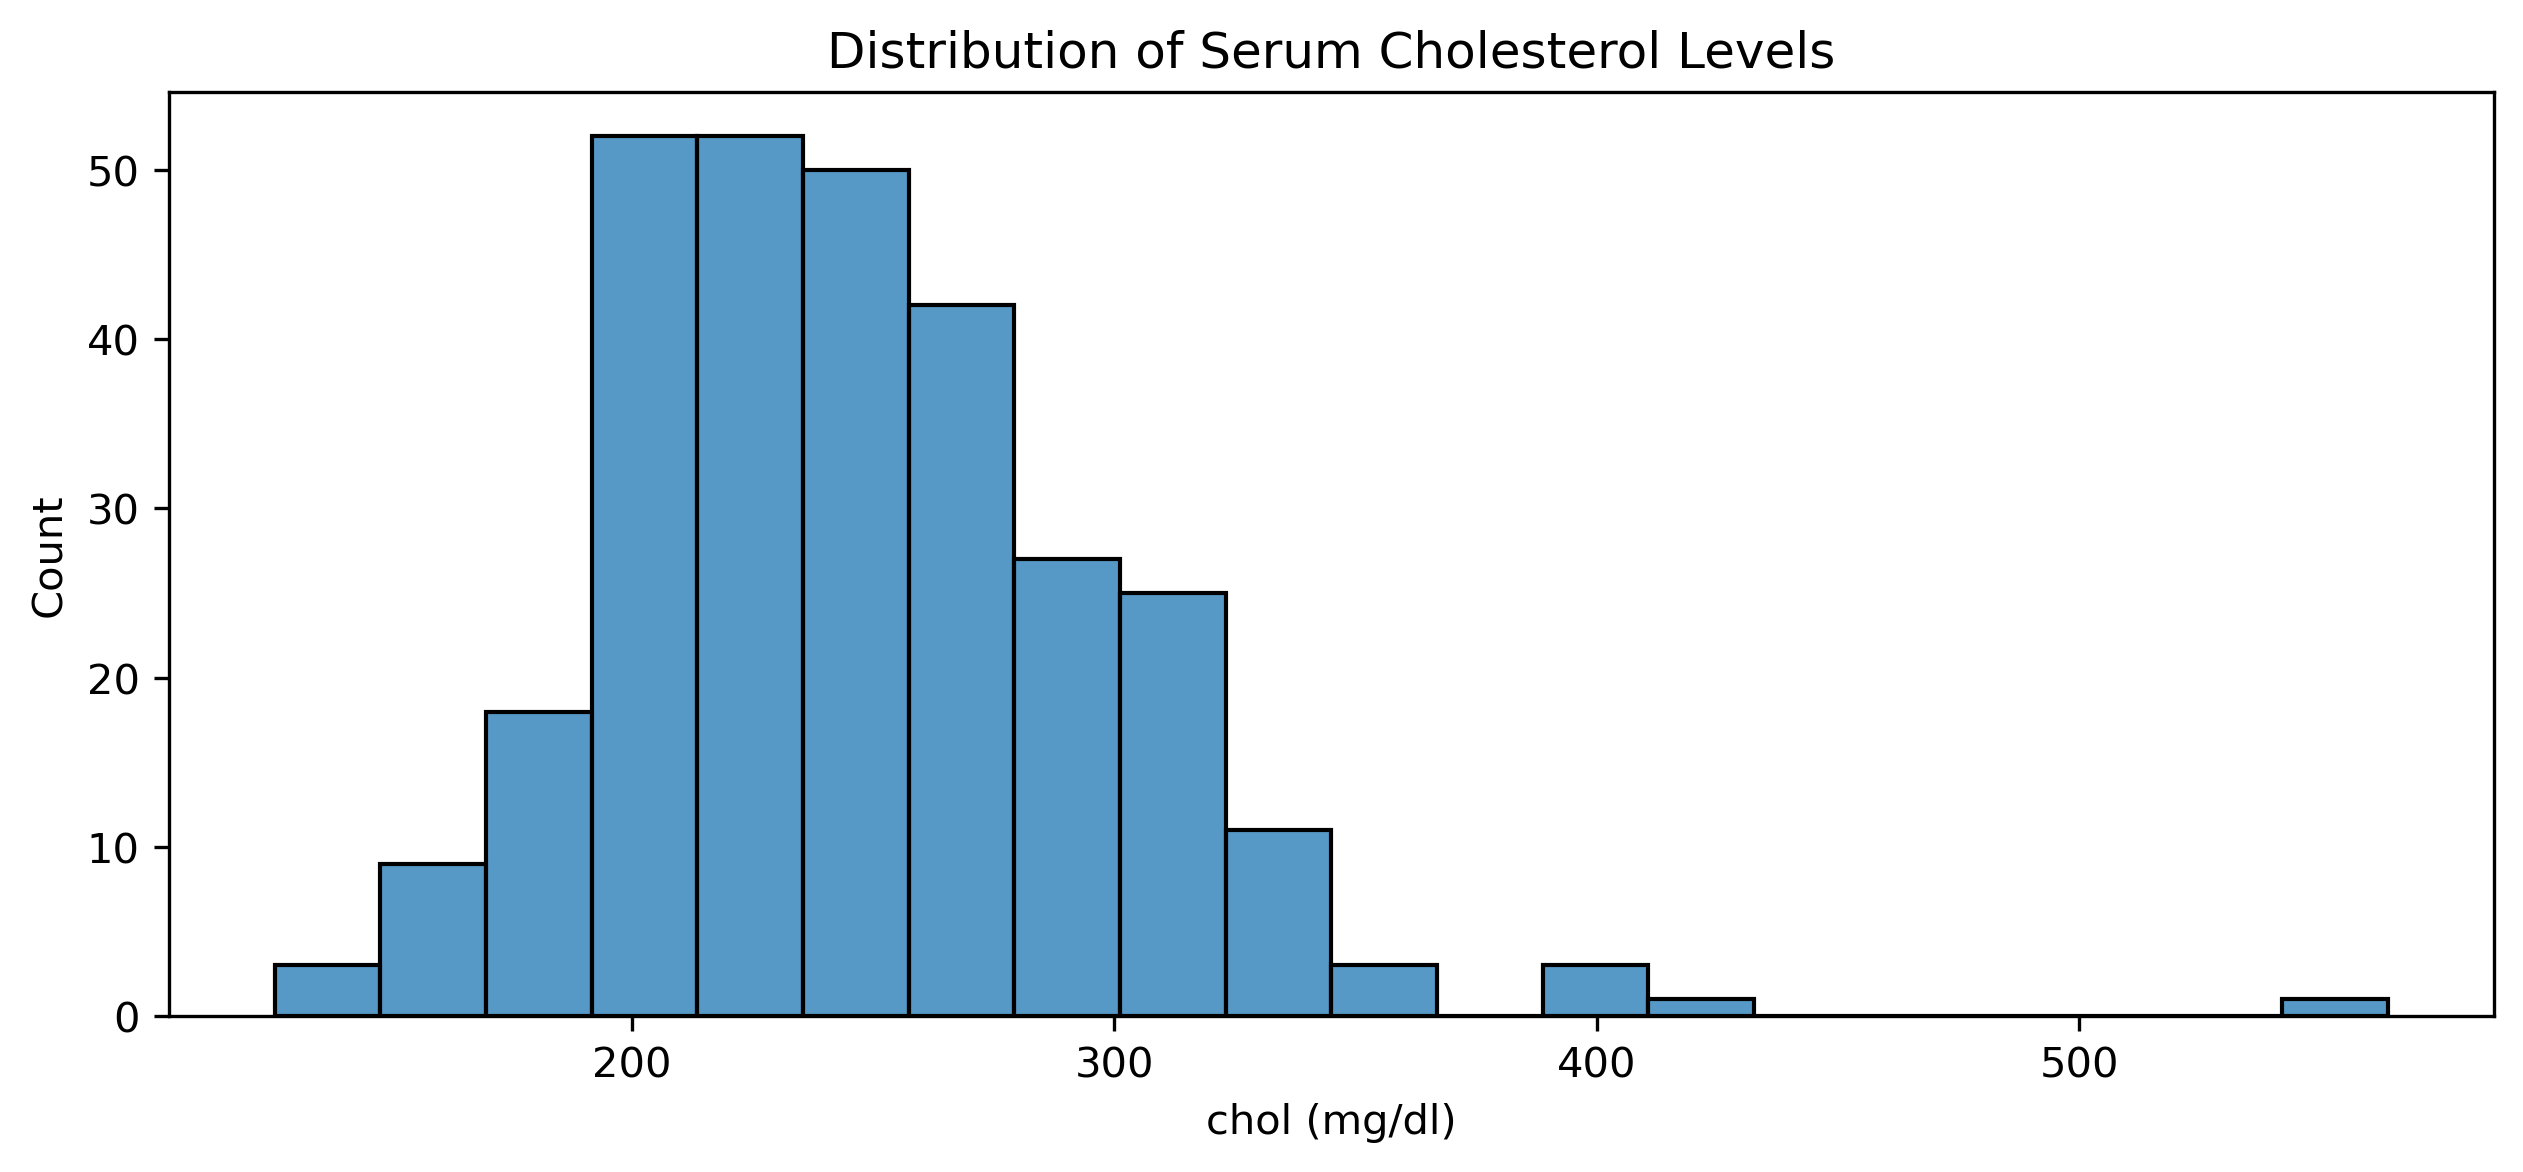

In [19]:
## Distribution of Cholesterol (Serum Cholesterol (mg/dl))

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'chol', bins = 20)

#Define labels
plt.xlabel('chol (mg/dl)')
plt.title('Distribution of Serum Cholesterol Levels')
plt.show()

In [20]:
#Investigate Outlier
df[df['chol'] > 400]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
48,65.0,0,3,140.0,417.0,1,2,157.0,0,0.8,1,1,3,0
120,63.0,0,4,150.0,407.0,0,2,154.0,0,4.0,2,3,7,4
151,67.0,0,3,115.0,564.0,0,2,160.0,0,1.6,2,0,7,0
179,56.0,0,4,134.0,409.0,0,2,150.0,1,1.9,2,2,7,2


In [21]:
#Check for skew
print(f'Cholesterol skew: {df['chol'].skew()}')

Cholesterol skew: 1.1180955225671279


**Comments:**
* The plot shows a right skewed distribution of serum cholesterol levels (skewness coeeficient of 1.12). This is mainly due to the presence of extreme outliers with levels above 400 mg/dl.
* Upon investigation, these outliers do not seem to be data errors but patients with unusually high cholesterol. Therefore, no further action is required.
* Furthermore, the distribution peaks with patients having cholesterol levels ranging from approximately 200 mg/dl to 280 mg/dl. The NHS threshold for high total cholesterol is approximately 247 mg/dl. Therefore, a large proportion of patients in this dataset could be considered to be borderline or have high cholesterol. However, this is to be expected again from a dataset which focuses on heart disease.

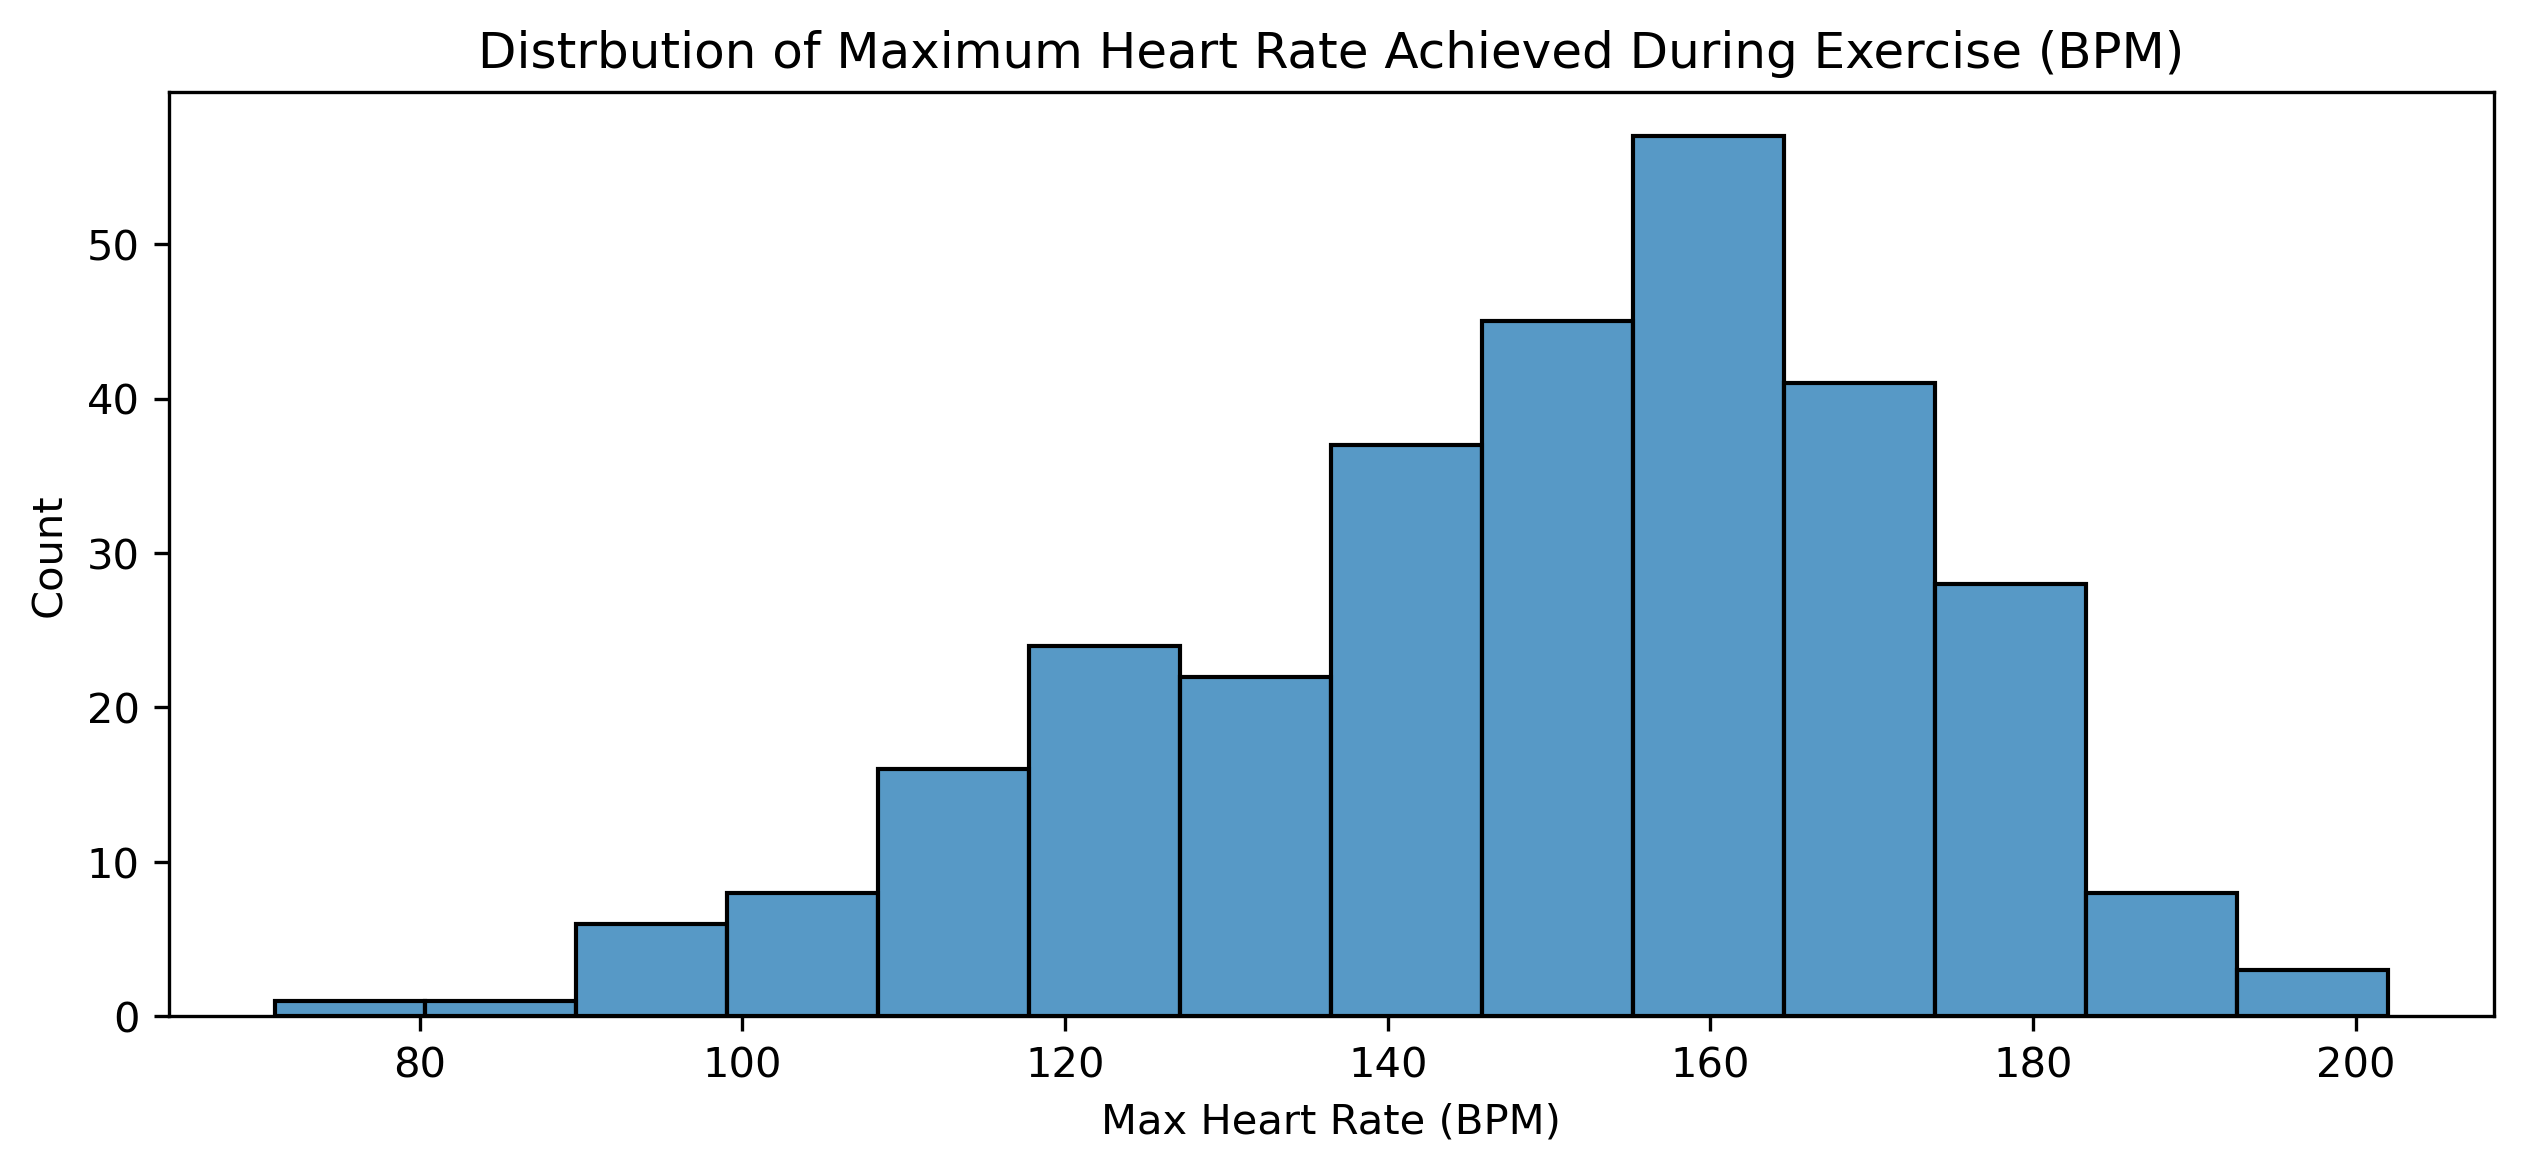

In [22]:
## Thalach Distribution (Maximum heart rate achieved during exercise (BPM))

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'thalach')

#Define labels
plt.xlabel('Max Heart Rate (BPM)')
plt.title('Distrbution of Maximum Heart Rate Achieved During Exercise (BPM)')
plt.show()

In [23]:
#Check for skew
print(f'thalach skew: {df['thalach'].skew()}')

thalach skew: -0.5365400799355459


**Comments:**
* The plot shows that the data is left-skewed (coefficeint of -0.54) for maximum heart rate achieved during exercise. This is due to a long tail caused by the presence of patients with lower maximum heart rate. However, this is to be expected as patients with heart disease commonly achieve lower maximum exercise heart rate. There are a number of causes for this. For instance:
    * The heart's inability to match its rates to the demands of physical exercise
    * Damage to the sinoatrial (SA) node (the heart's natural pacemaker) where it may not fire signals fast enough
    * Ischaemia - where narrowed arteries restrict oxyen supply to the heart muscle
    * Structural weakness, where heart walls are too weak or stiff and therefore may not handle the structural stress of rapid beating. 

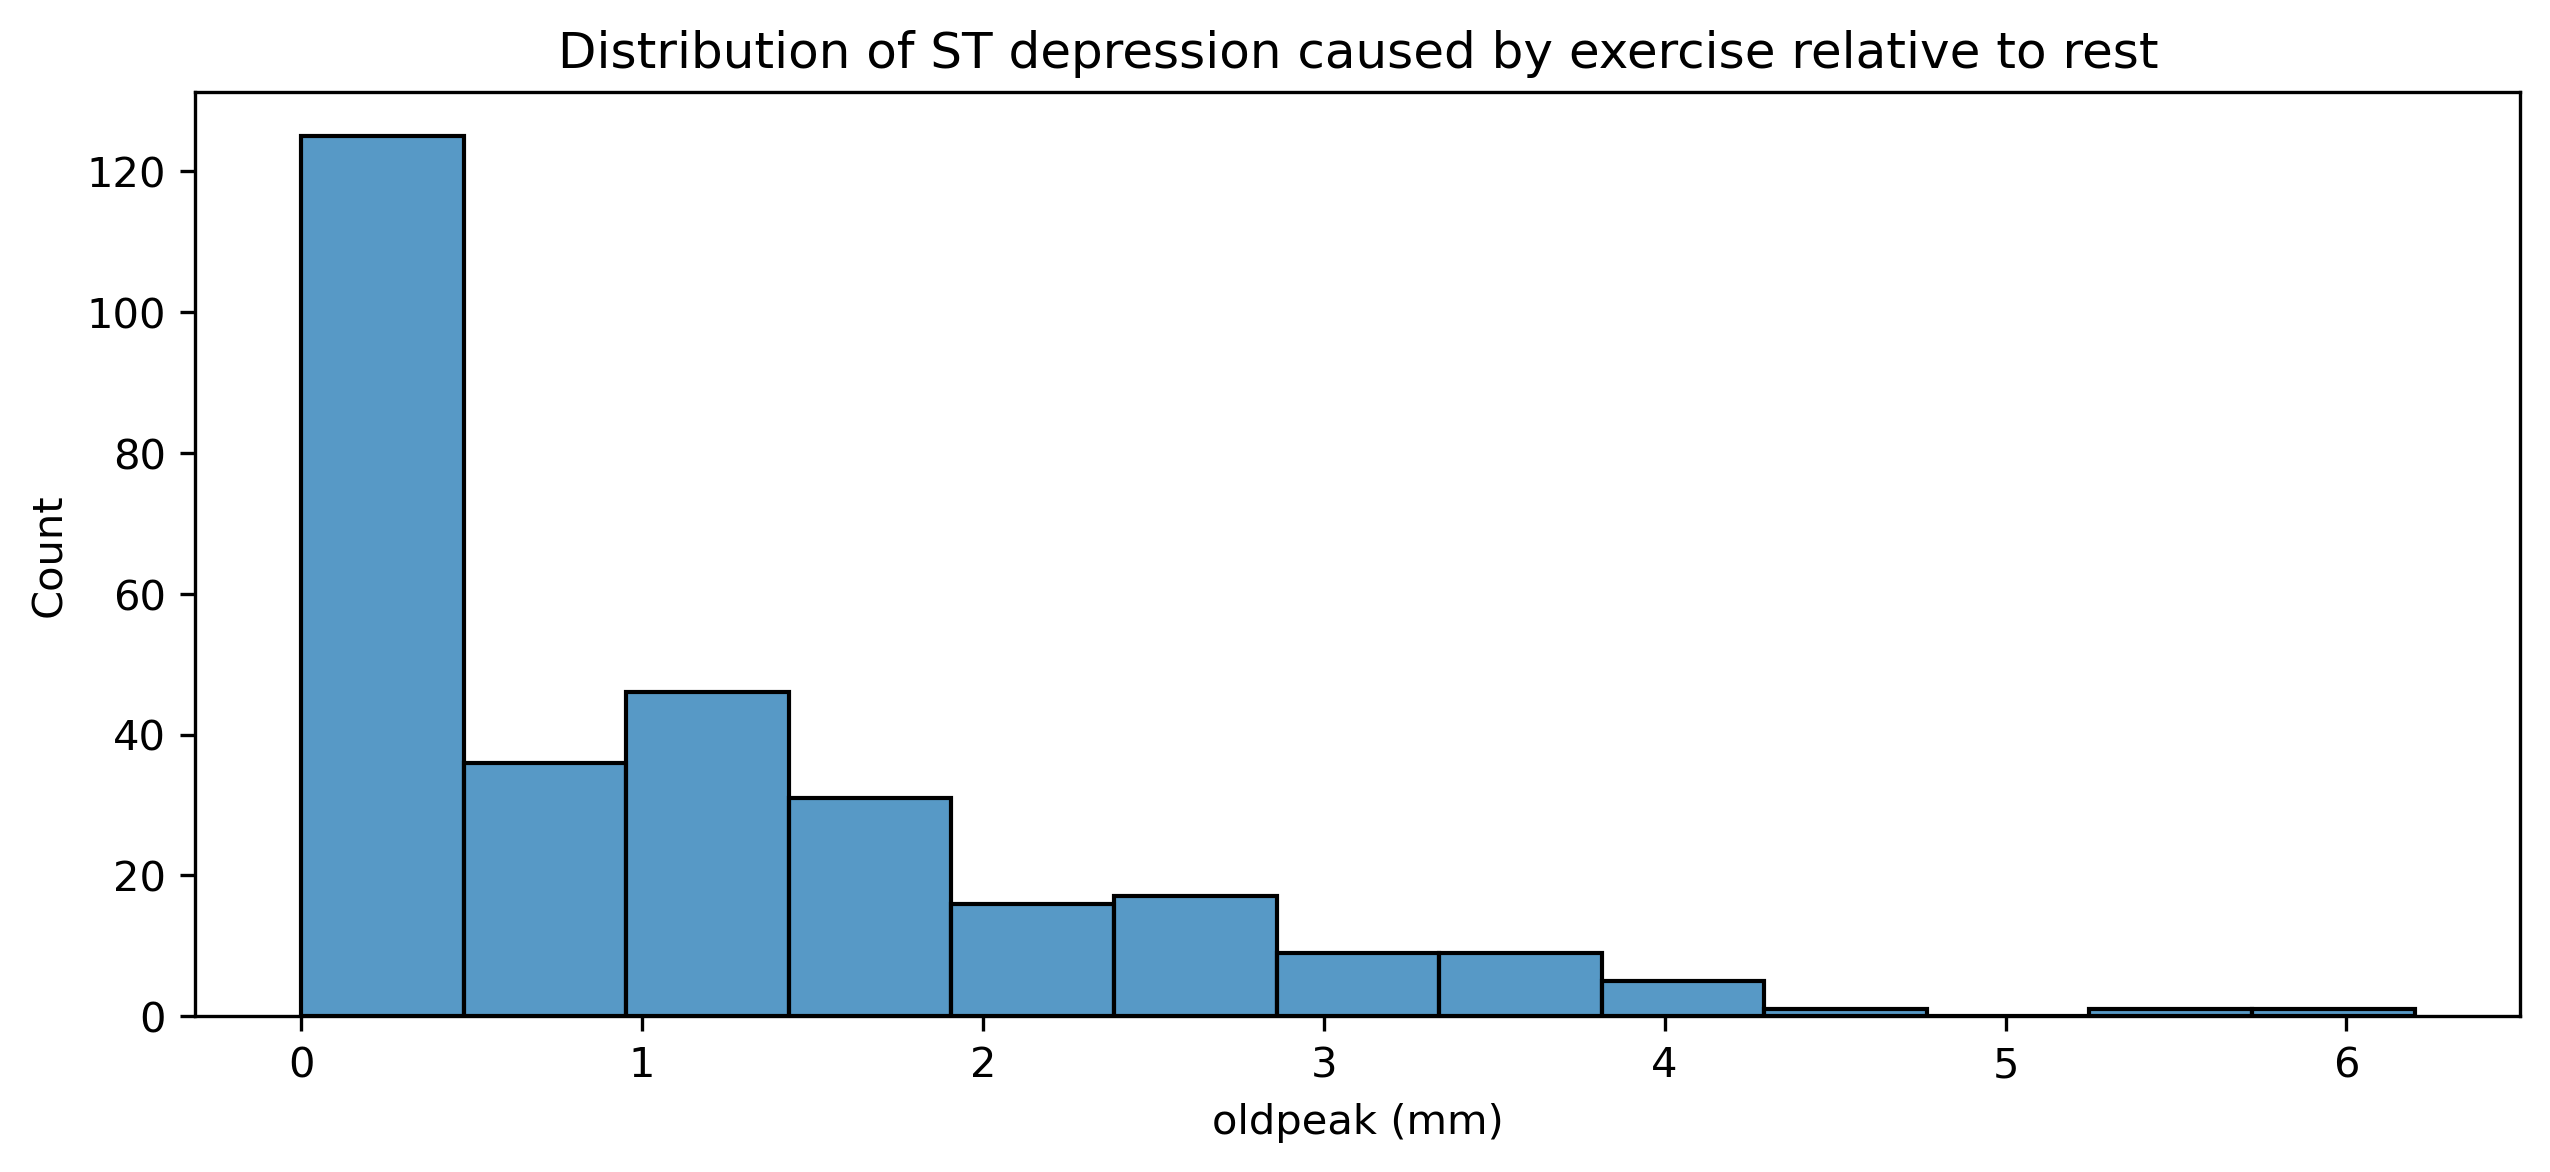

In [24]:
## Distribution of oldpeak (ST depression caused by exercise relative to rest)

# Plot figure
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'oldpeak')

#Define Labels
plt.title('Distribution of ST depression caused by exercise relative to rest')
plt.xlabel('oldpeak (mm)')
plt.show()

In [25]:
#Check for skew
print(f'oldpeak skew: {df['oldpeak'].skew()}')

oldpeak skew: 1.2471313241482946


**Comments:**
* The data is heavily right skewed (coefficient of 1.25), where there is a long tail caused by patients with abnormally high ST depression.
* The guidelines provided by the National Institute for Health and Care Excellence (NICE) suggest:
    * Above or equal to 1.00 mm = A significant sign of myocardial ischemia
    * Above or equal to 2.00 mm = highly significant and indicating coronary artery disease
    * Above or equal to 5.00 mm = An Absolute Stopping threshold, suggesting that treadmill tests need to be terminated and could possibly be a sign of Left Main Stem (LMS) Coronary Artery Disease and Three-Vessel Disease (both severe stages of coronary artery disease).
* The data peaks at around 0 to 0.5, This suggests that there is a large proportion of patients within this dataset with normal ST depression.
* However, the long tail shows a proportion of patients who have ST depression above 1 mm and 2mm - either indivating myocardial ischemia or coronary artery disease.
* Furthermore, there is a small proportion of patients with an ST depression above 5 mm. This could represent a more severe form of Coronary Artery Disease.

## Analysis of Categorical Features

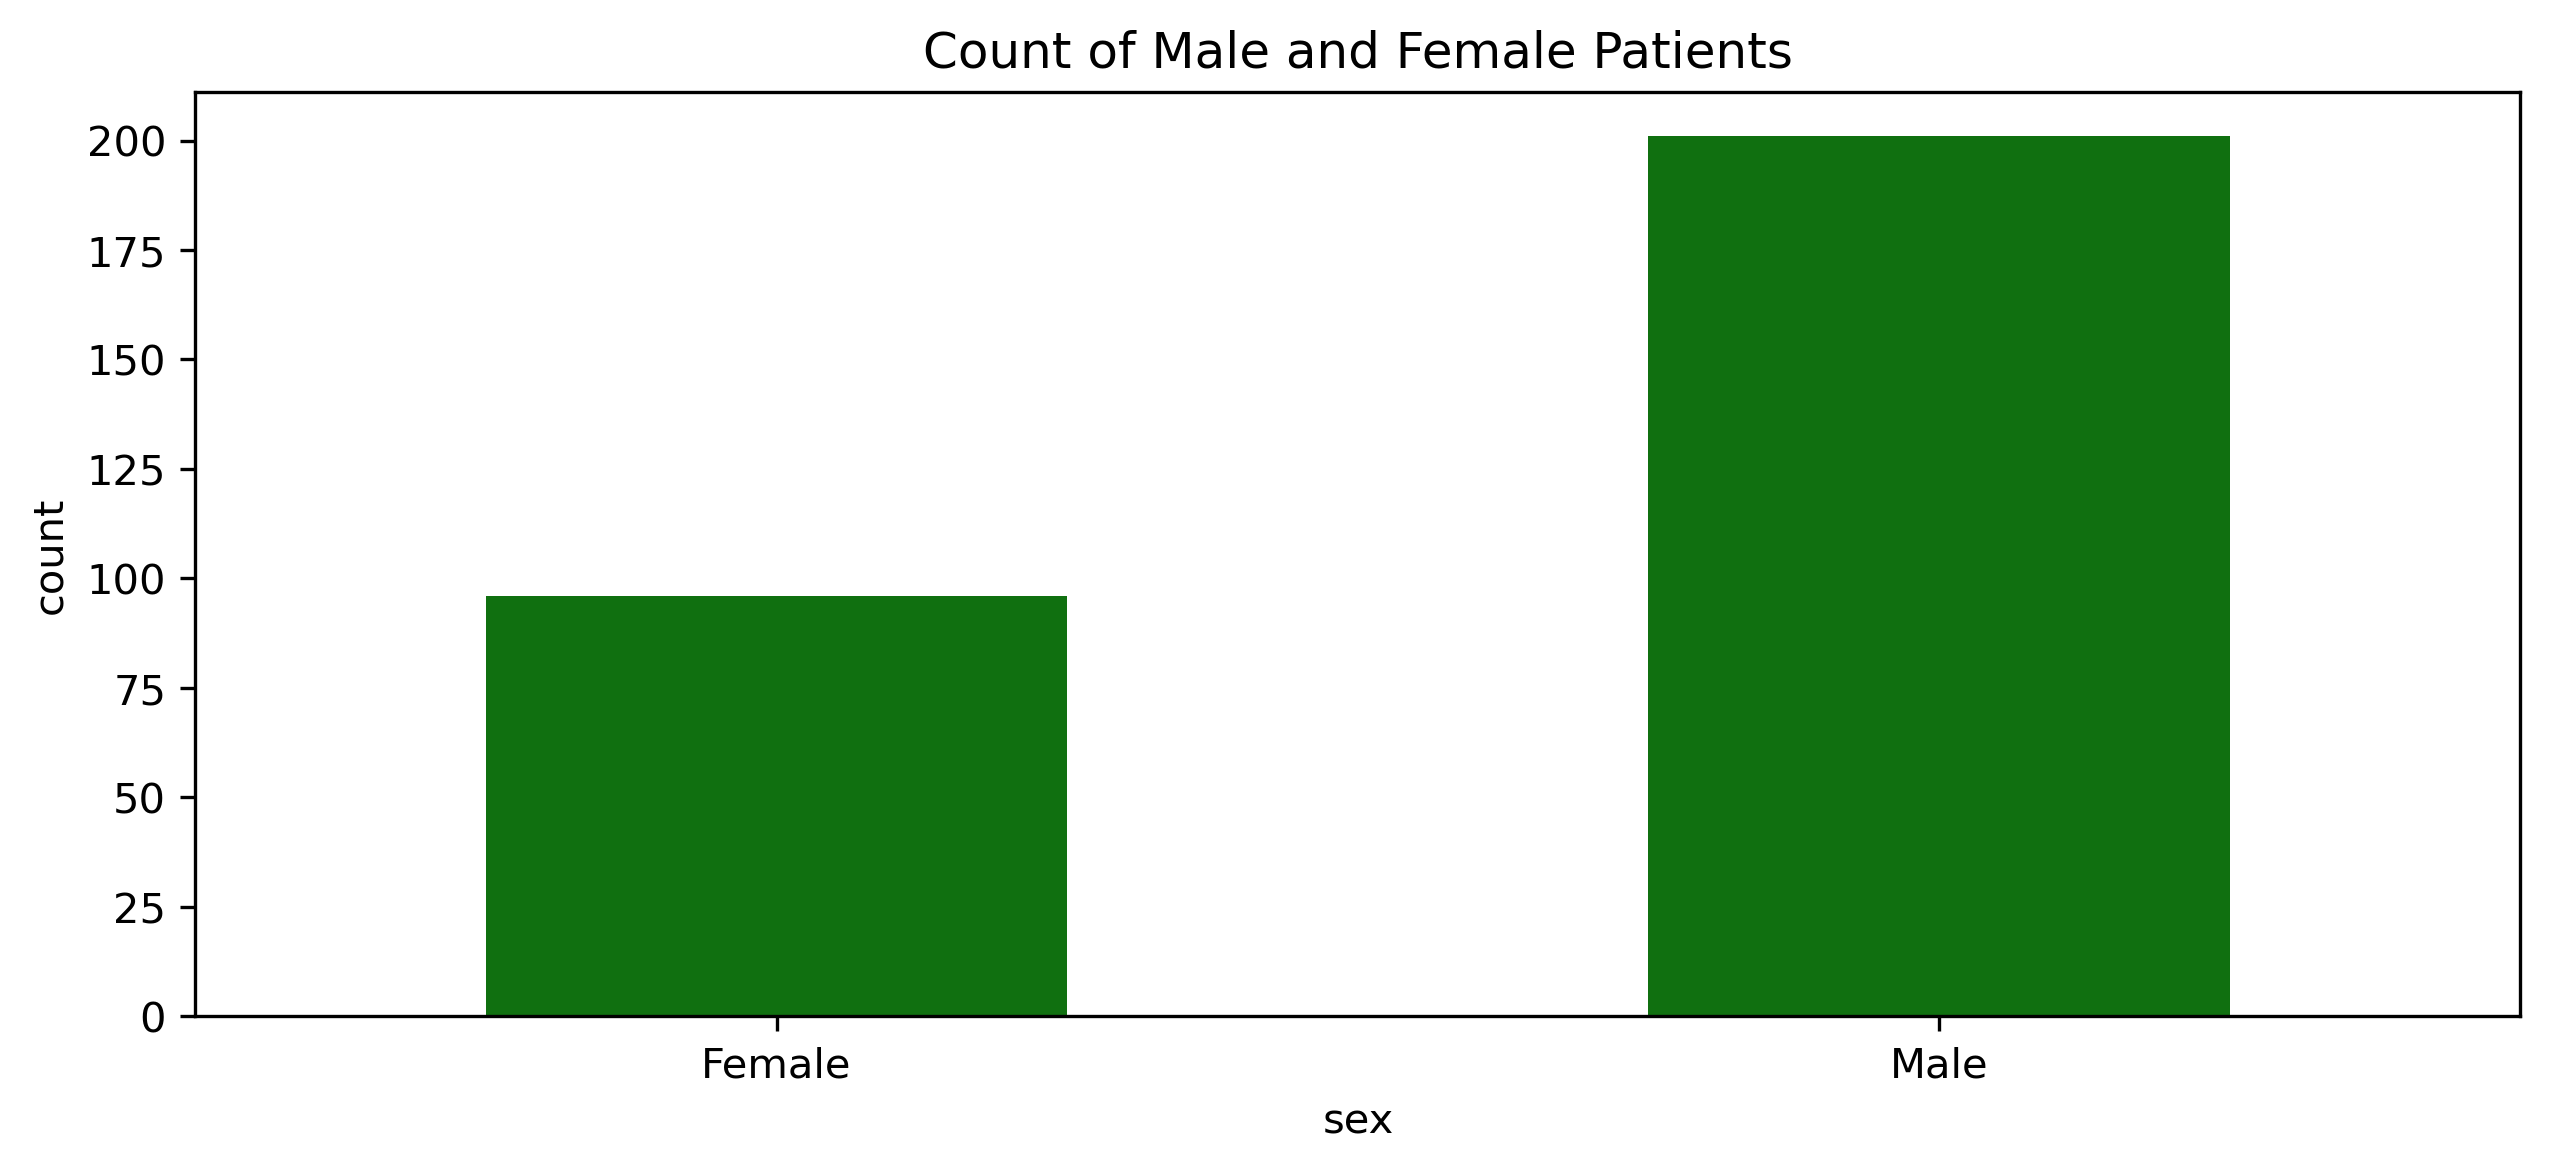

In [26]:
#Sex Countplot

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'sex', width = 0.5, color = 'green')

#Define labels
ax.set_xticks([0,1])
ax.set_xticklabels(['Female', 'Male'])
plt.title('Count of Male and Female Patients')

plt.show()

**Comments:**
* The plot shows that there is approximately double the amount of male patients in this dataset compared to female patients.
* However, this could be expected as studies have shown that males are more likely to be diagnosed with coronary artery disease than females, due to earlier age of onset. "Premature" CAD is clinically defined as a diagnosis before 45 years old in males, in comparison to before 55 years old in women. Therefore, this leads to more male representation in heart-disease datasets.

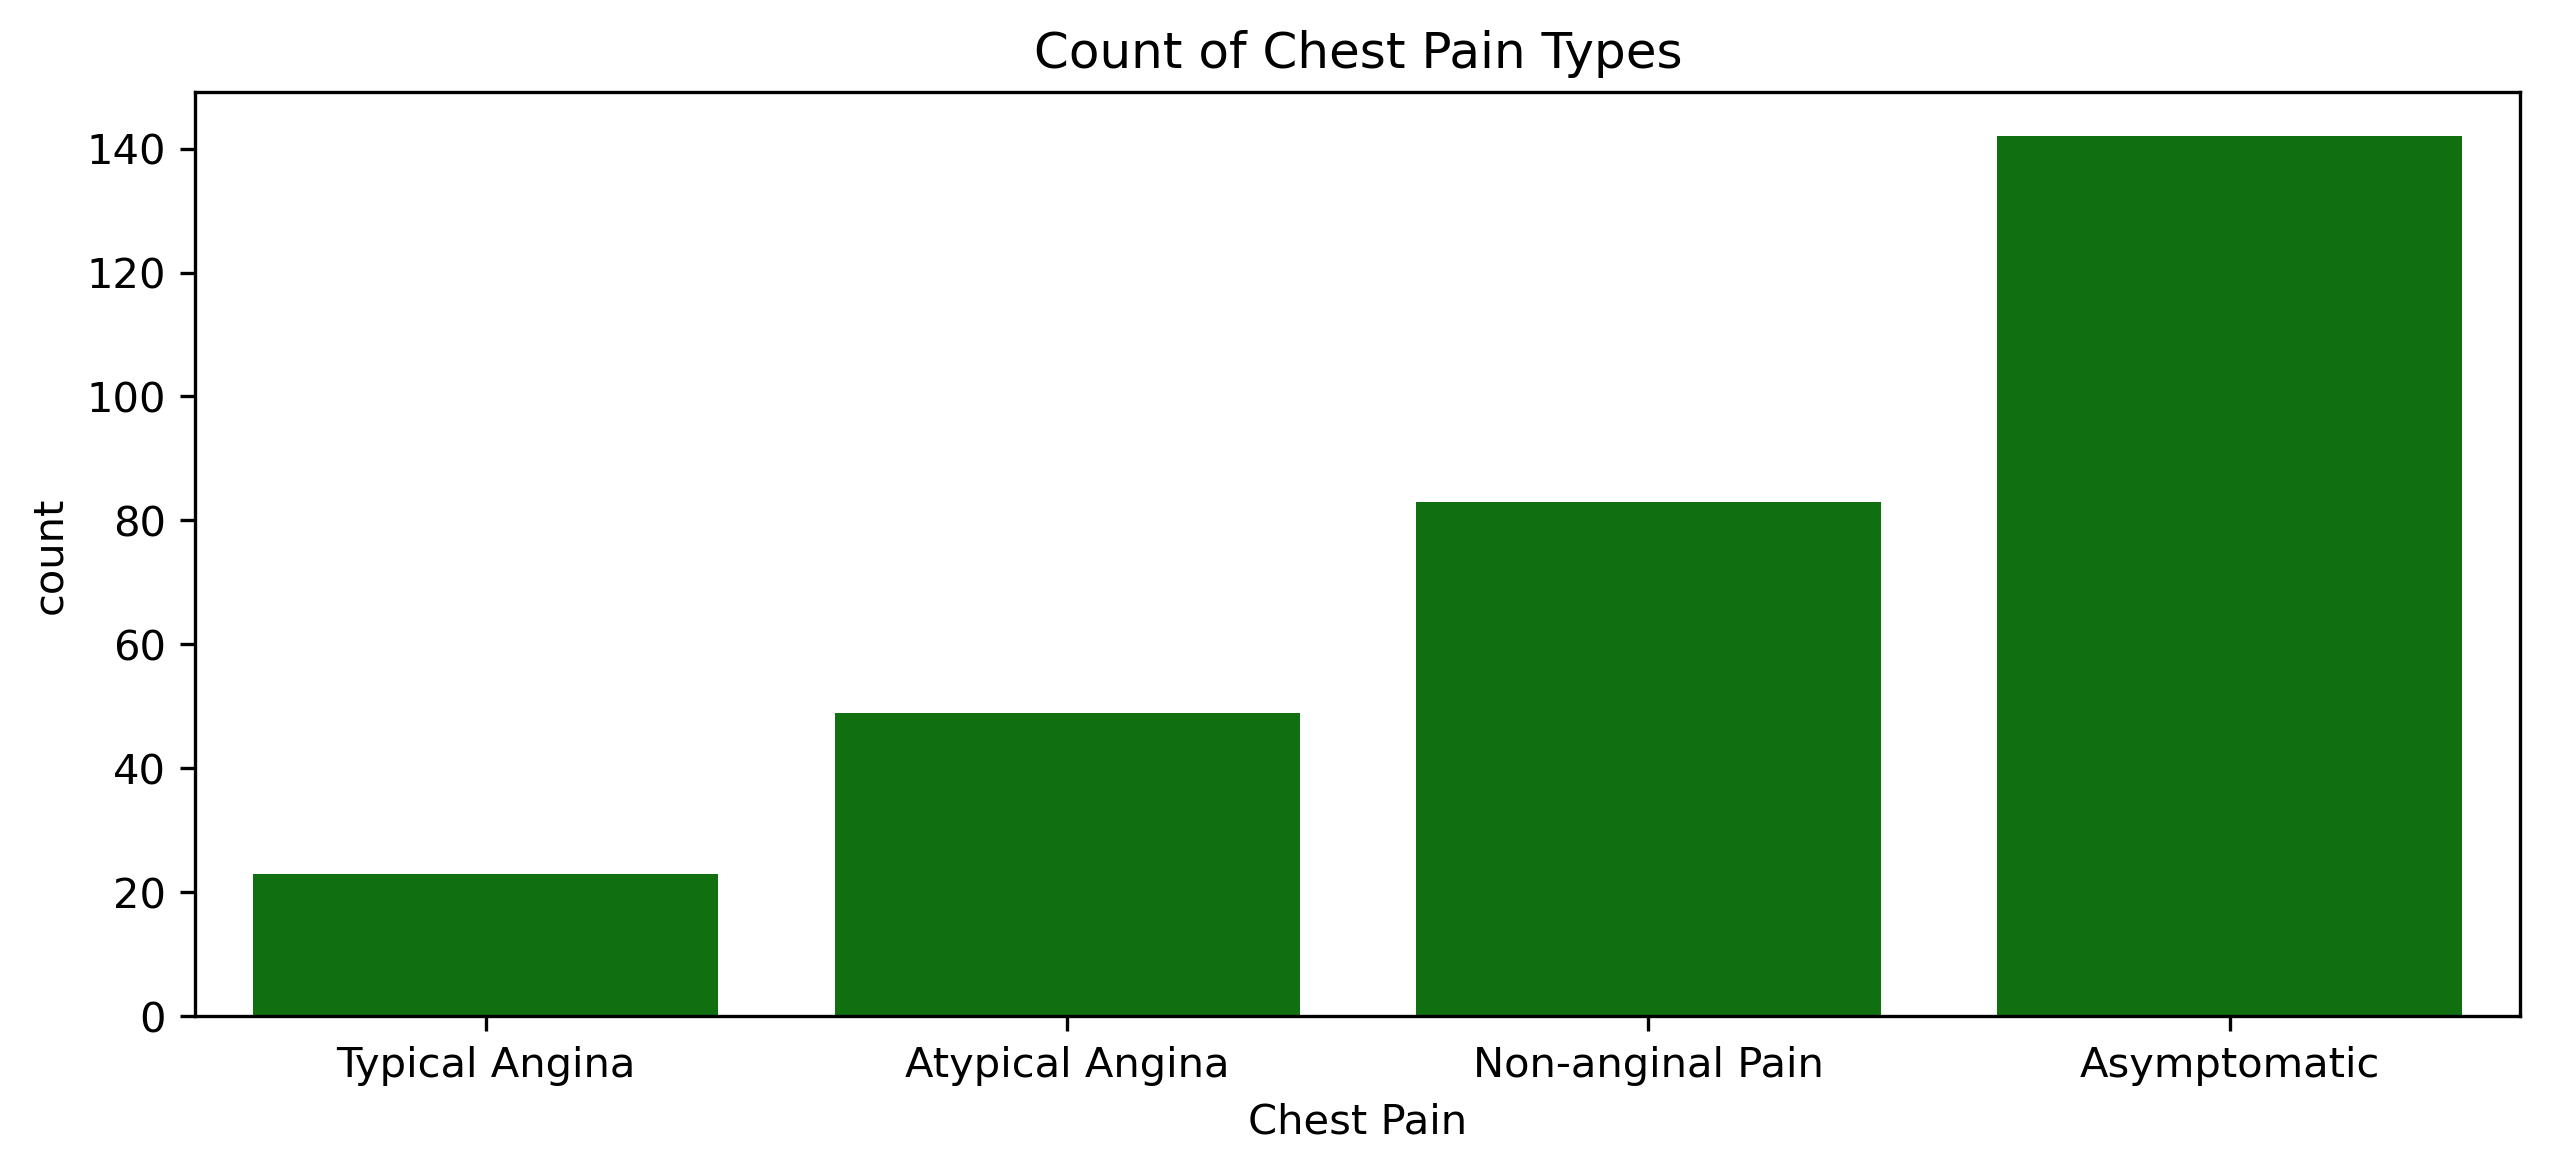

In [27]:
# Chest Pain Countplot

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax1 = sns.countplot(data = df, x = 'cp', color = 'green')

#Define labels
ax1.set_xticks([0, 1, 2, 3])
ax1.set_xticklabels(['Typical Angina', 'Atypical Angina', 'Non-anginal Pain', 'Asymptomatic'])
plt.xlabel('Chest Pain')
plt.title('Count of Chest Pain Types')


plt.show()

**Comments:**
* The plot shows that the largest proportion of patients are asymptomatic. However, patients can still be asymptomatic despite having Cardiovascular Artery Disease, this could be due to silent ischemia or the presence of advanced diabetes.
  
* Furthermore, the plot shows that there was a small proportion of patients with typical angina. Hesse et al. (2023) suggested that typical angina is more prevalent in older patients and has a higher incidence of obstructive CAD (a more severe form). This could be one of the reasons why typical angina makes up the smallest subset of patients, as the dataset is primarily composed of middle-aged patients.
  
* Furthermore, atypical anginal and non-anginal pain is found to be common in CAD patients but are less strongly associated with severe forms such as obstructive CAD.

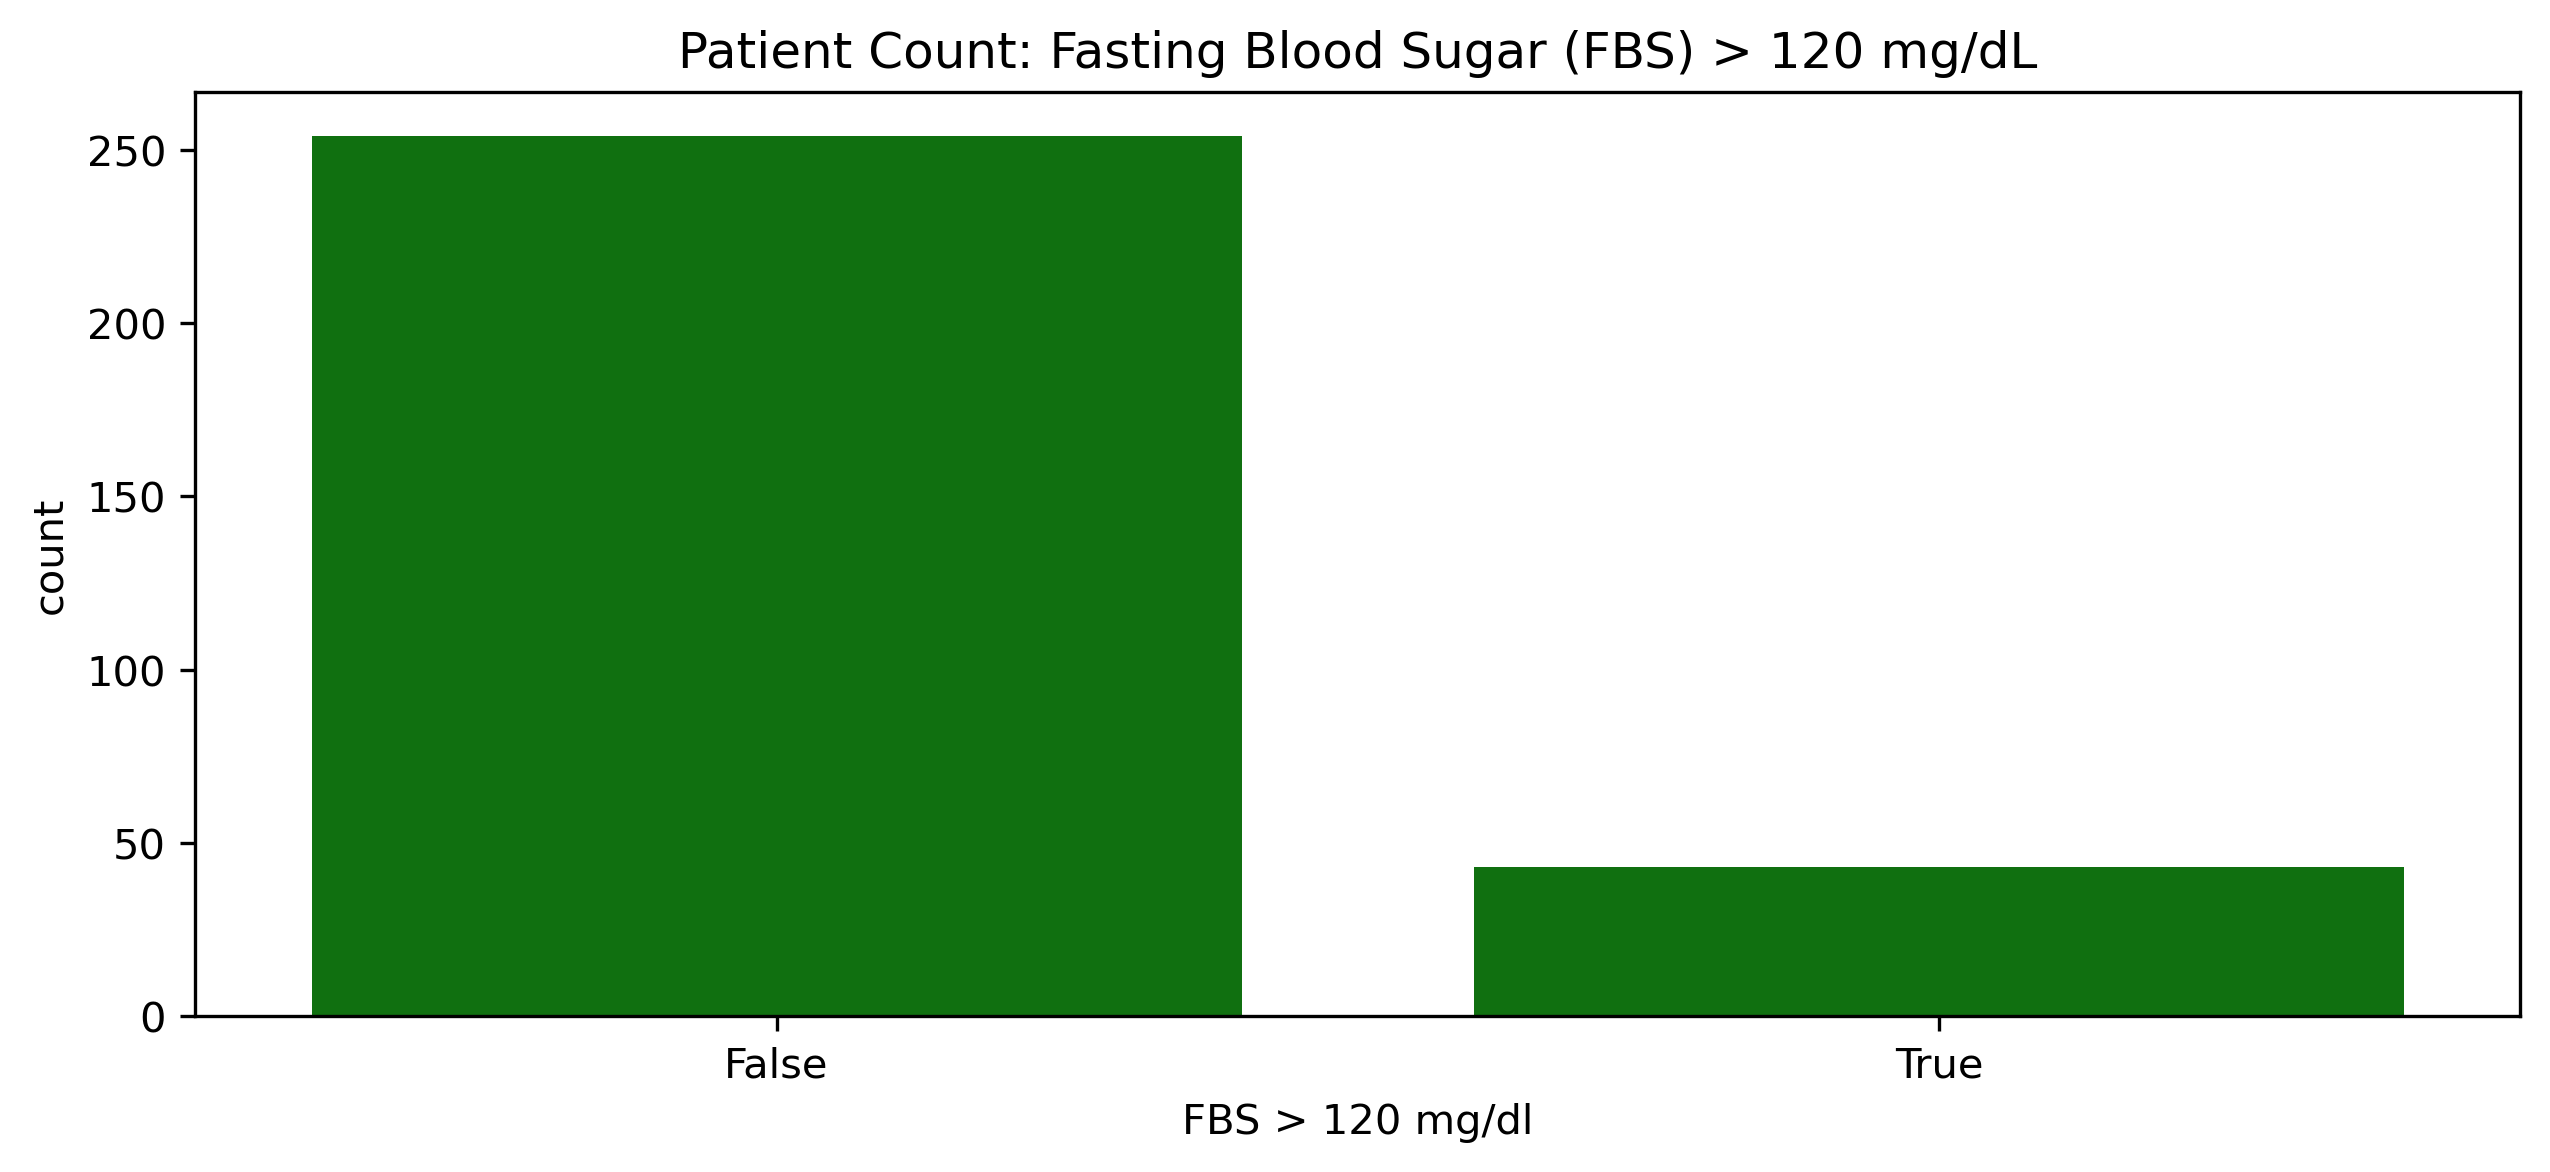

In [28]:
#Fasting Blood Sugar >120 countplot

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'fbs', color = 'green')

#Define labels
ax.set_xticks([0, 1])
ax.set_xticklabels(['False', 'True'])
plt.xlabel('FBS > 120 mg/dl')
plt.title('Patient Count: Fasting Blood Sugar (FBS) > 120 mg/dL')


plt.show()

**Comments:**
* The plot shows that only a small amount of patients have a high fasting blood sugar above 120 mg/dl.
* A high fasting blood sugar could potentially signal prediabetes/diabetes and is a contributing factor to the diagnosis of CAD as it can cause endothelial dysfunction and hence damage the inner lining of blood vessels, causing the build-up of fatty acids and lipids. Furthermore, it promotes oxidative stress, enhancing inflammation inside the artery walls. These factors directly contribute to atherosclerosis (the build-up and calcification of plaques which cause the narrowing of arteries).
* However, an elevated FBS is only a risk factor for CAD. Other factors also drive coronary artery disease, such as lifestyle/environmental influences, cholesterol levels, pre-existng conditions etc. This could serve as an explanation for why a significant majority of patients (some with a diagnosis and some without) in this heart disease dataset test 'False' for elevated FBS.

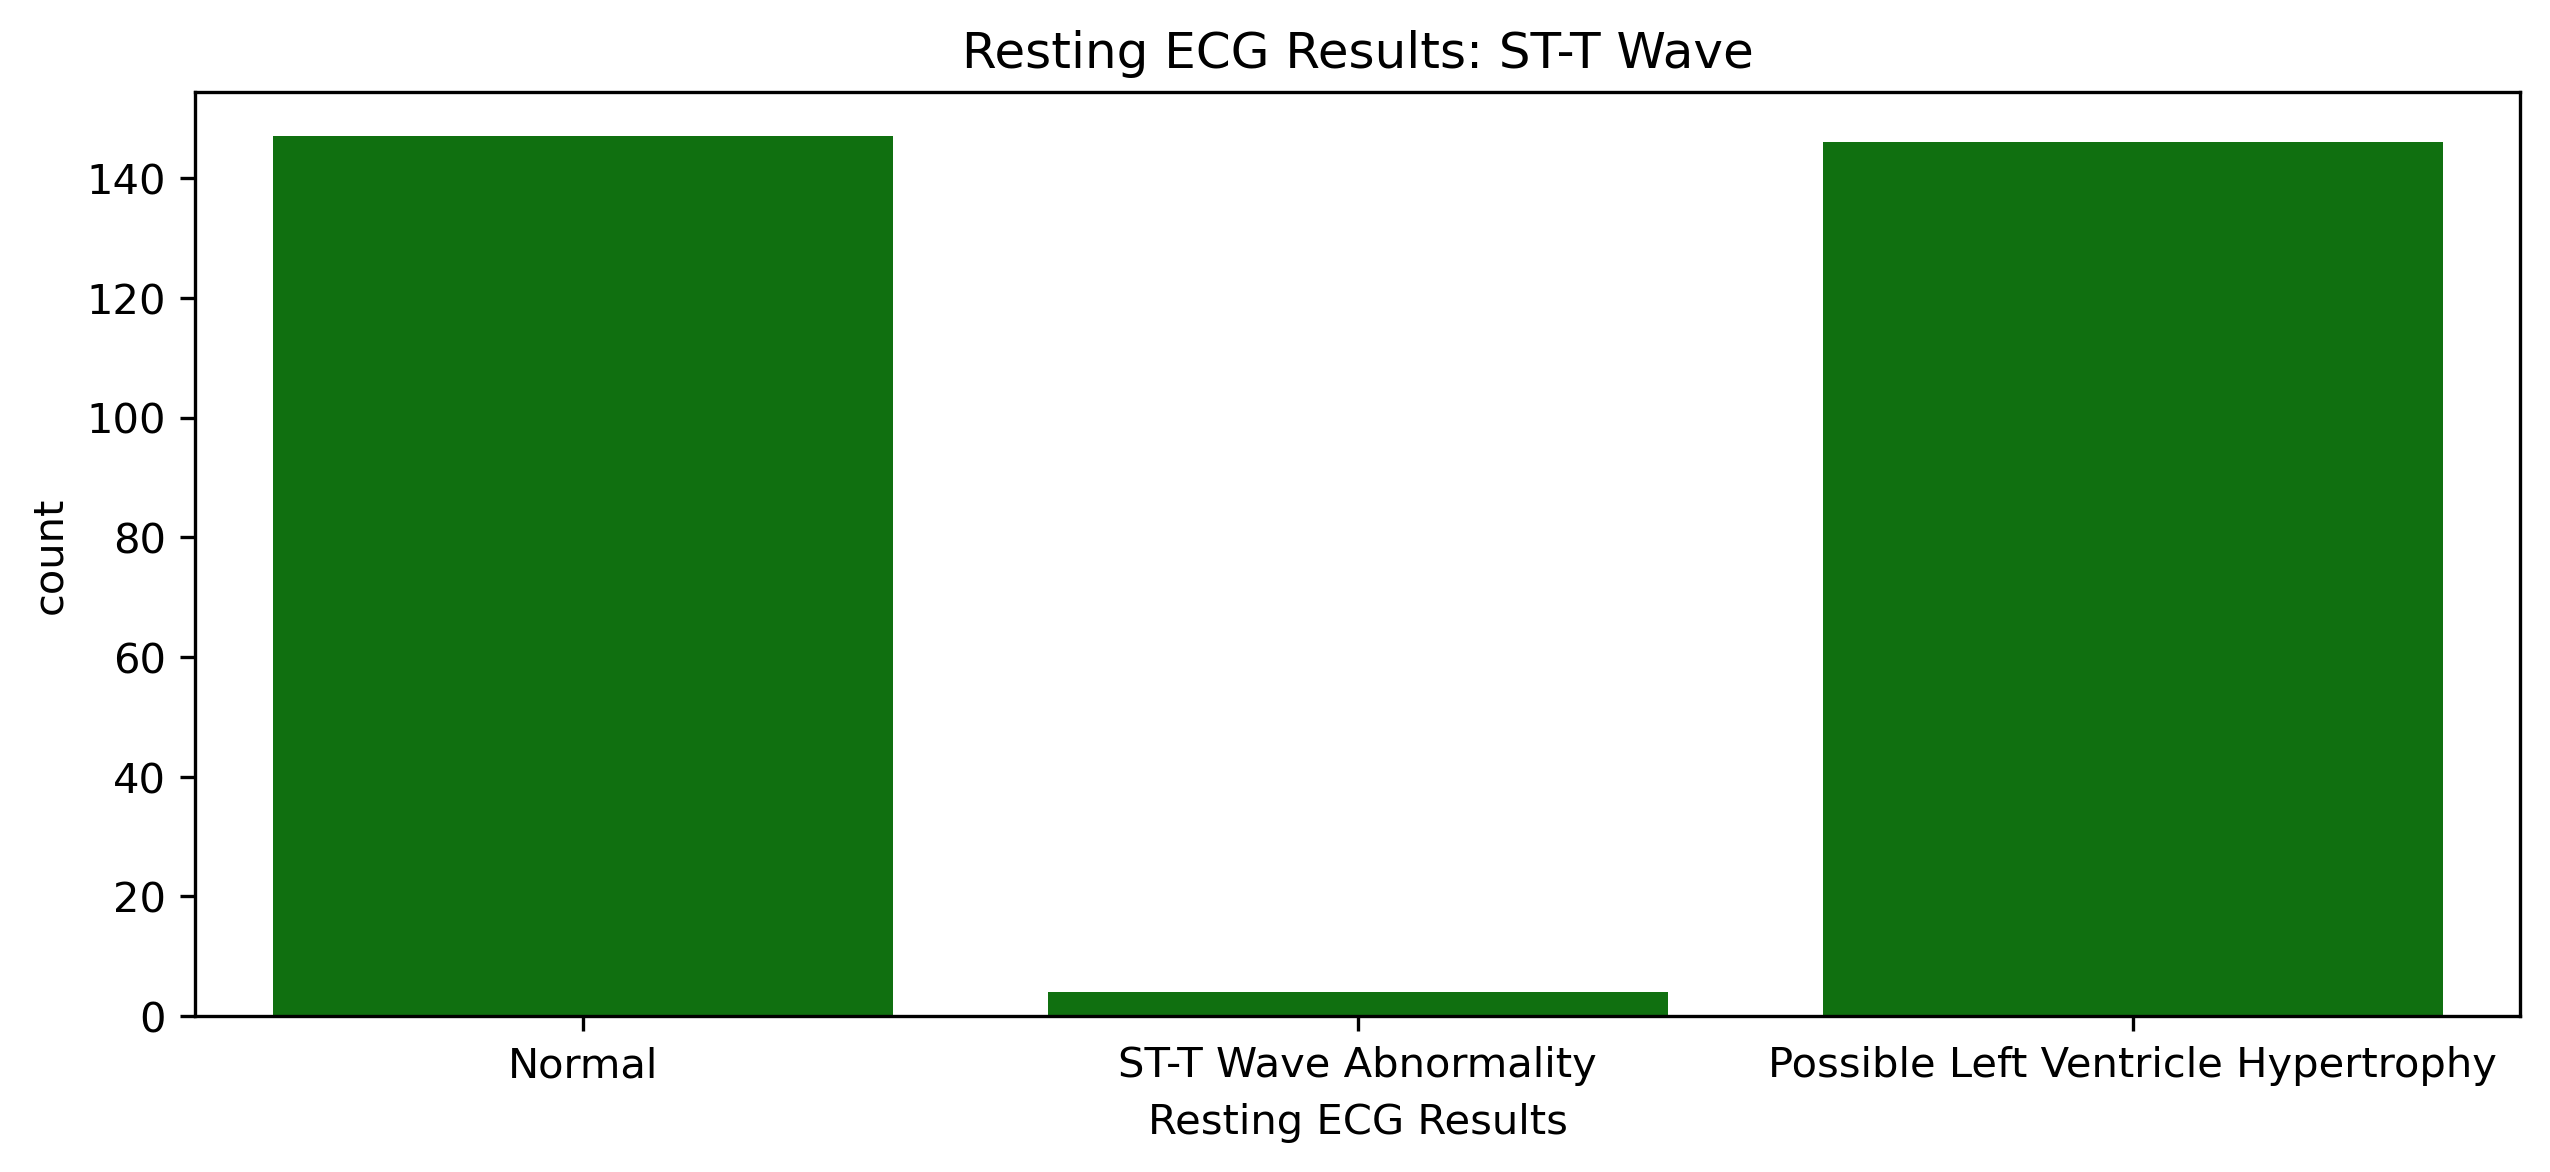

In [29]:
#restecg Countplot (results from resting ECG)

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'restecg', color = 'green')

#Define labels
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Normal', 'ST-T Wave Abnormality', 'Possible Left Ventricle Hypertrophy'])
plt.xlabel('Resting ECG Results')
plt.title('Resting ECG Results: ST-T Wave')


plt.show()

**Comments:**
* The plot shows that there is an approximate equal distribution between a normal resting ECG and an ECG that suggests possible left ventricle hypertrophy.
* There is a small proportion of patients with ST-T Wave Abnormalities which represent a minority in the dataset.
* Left Ventricular Hypertrophy (the thickening of the wall in the left ventricle, making it hard for the heart to pump blood efficiently) is a very common factor in CAD, often caused by high blood pressure. This explains why a large majority of patients in this dataset are in this category.
* There is only a small proportion of patients which show ST-T wave abnormalities. However, this is not unusual as these are less common in resting ECGs and more present during exercise. Additionally, LVH may mask ST-T changes.

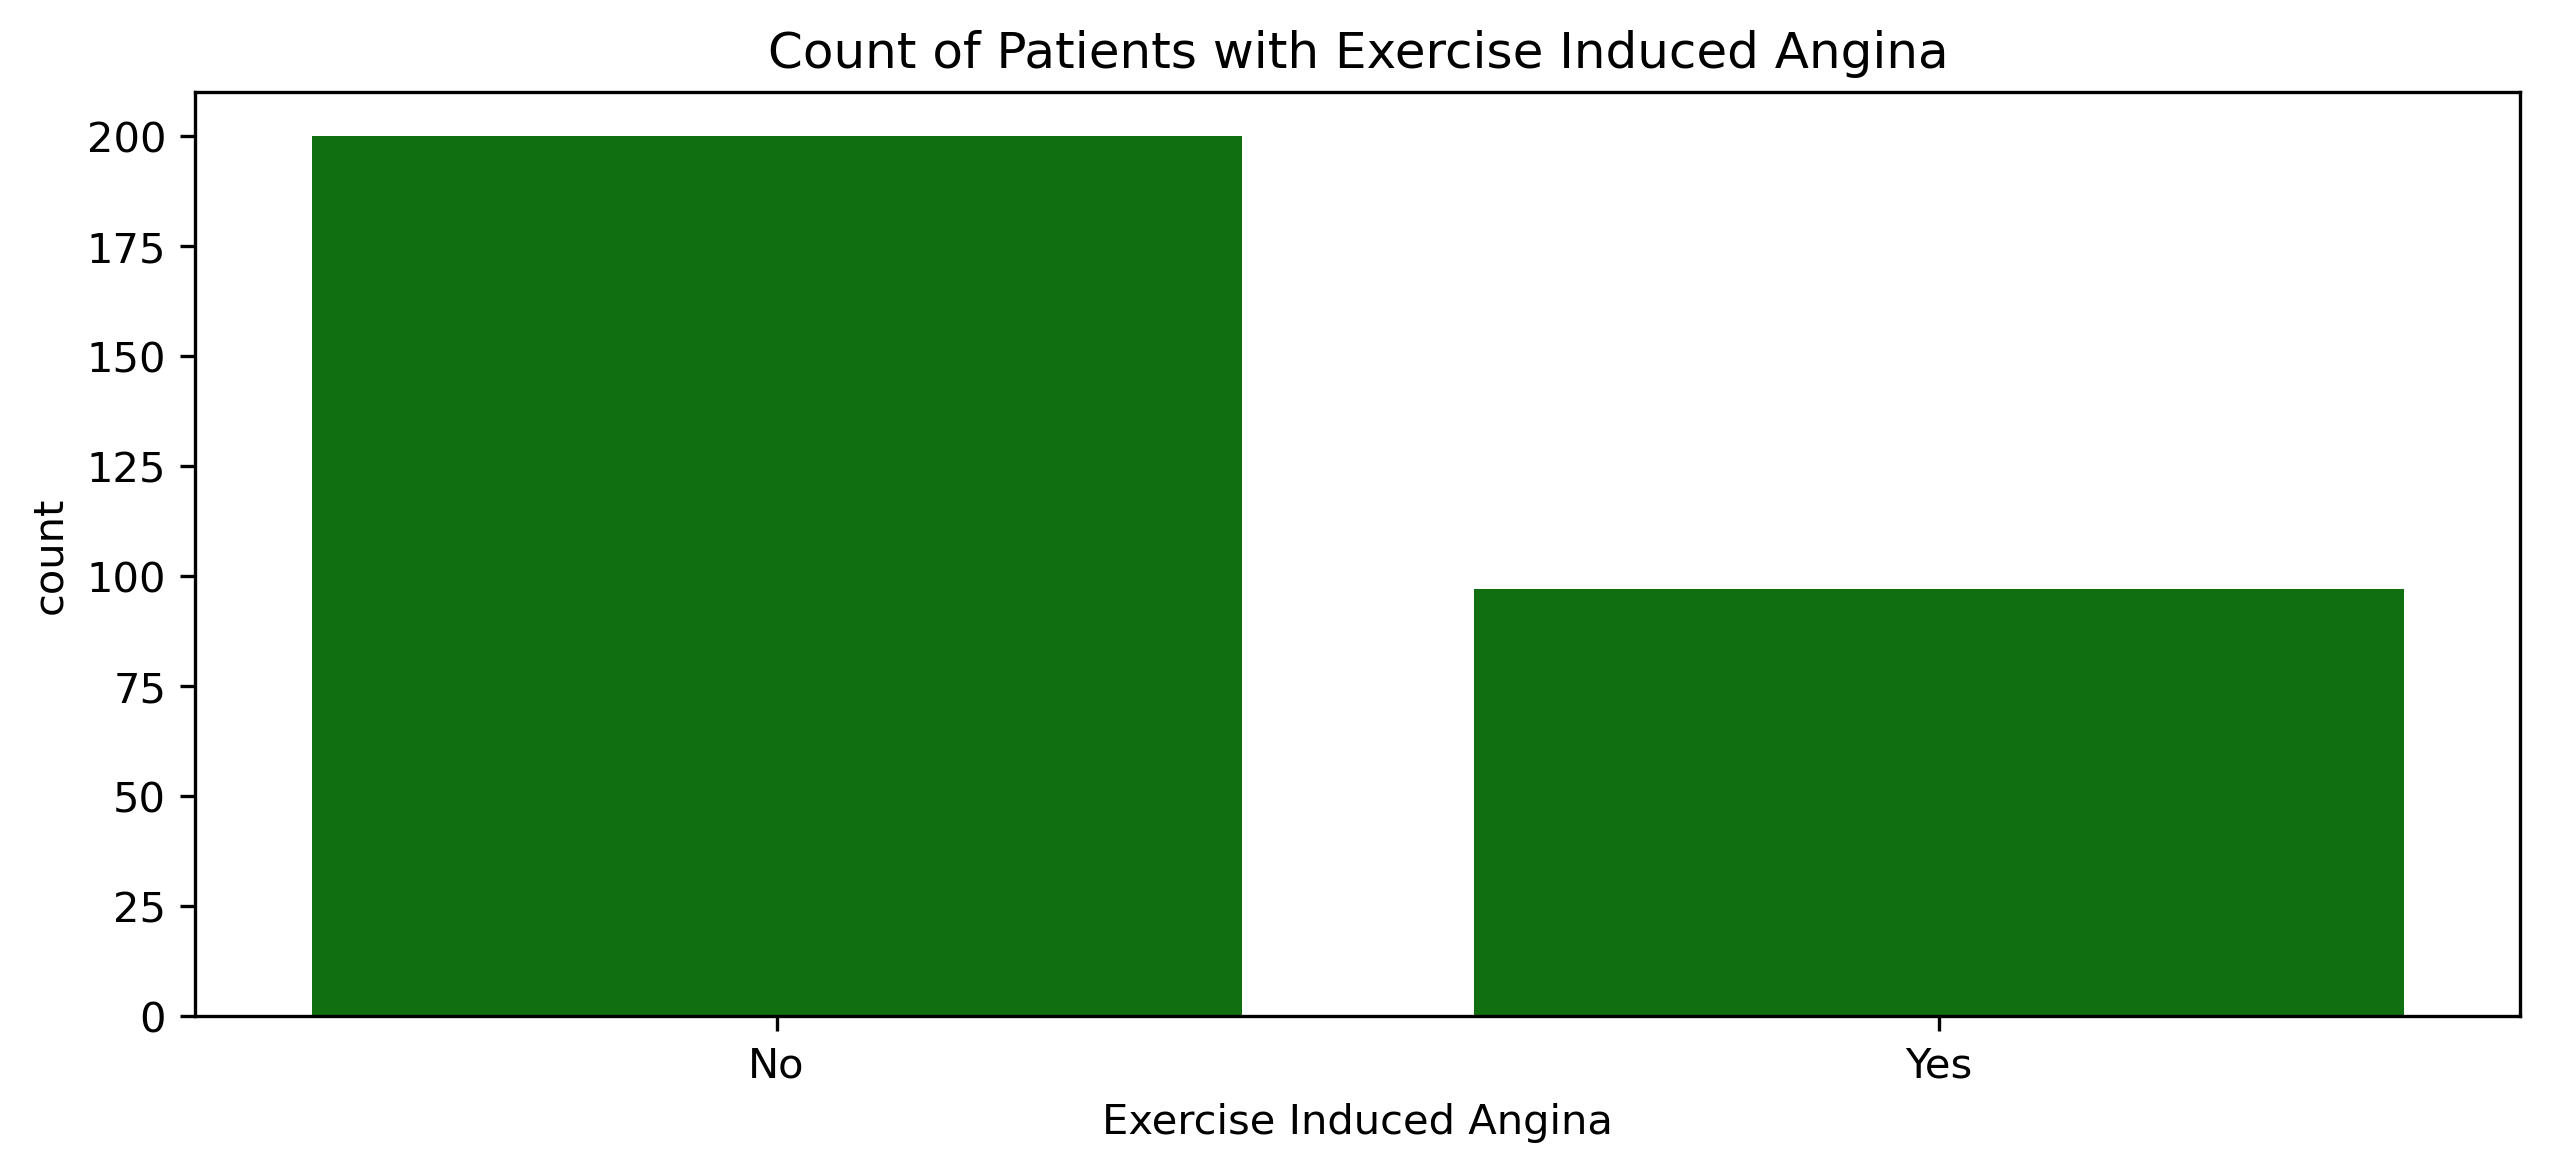

In [30]:
#Exang Analysis - Exercise-induced analysis

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'exang', color = 'green')

#Define labels
ax.set_xticks([0, 1])
ax.set_xticklabels(['No', 'Yes'])
plt.xlabel('Exercise Induced Angina')
plt.title('Count of Patients with Exercise Induced Angina')

plt.show()

**Comments:**
* The plot shows that a larger majority of patients do not have exercise-induced angina. This could be due to patients in the dataset having no diagnosis of CAD and patients with CAD not always presenting with exercise induced angina. Patients who do not present with this kind of angina might be experiencing silent ischemia or atypical symptoms such as shortness of breath and unusual fatigue.

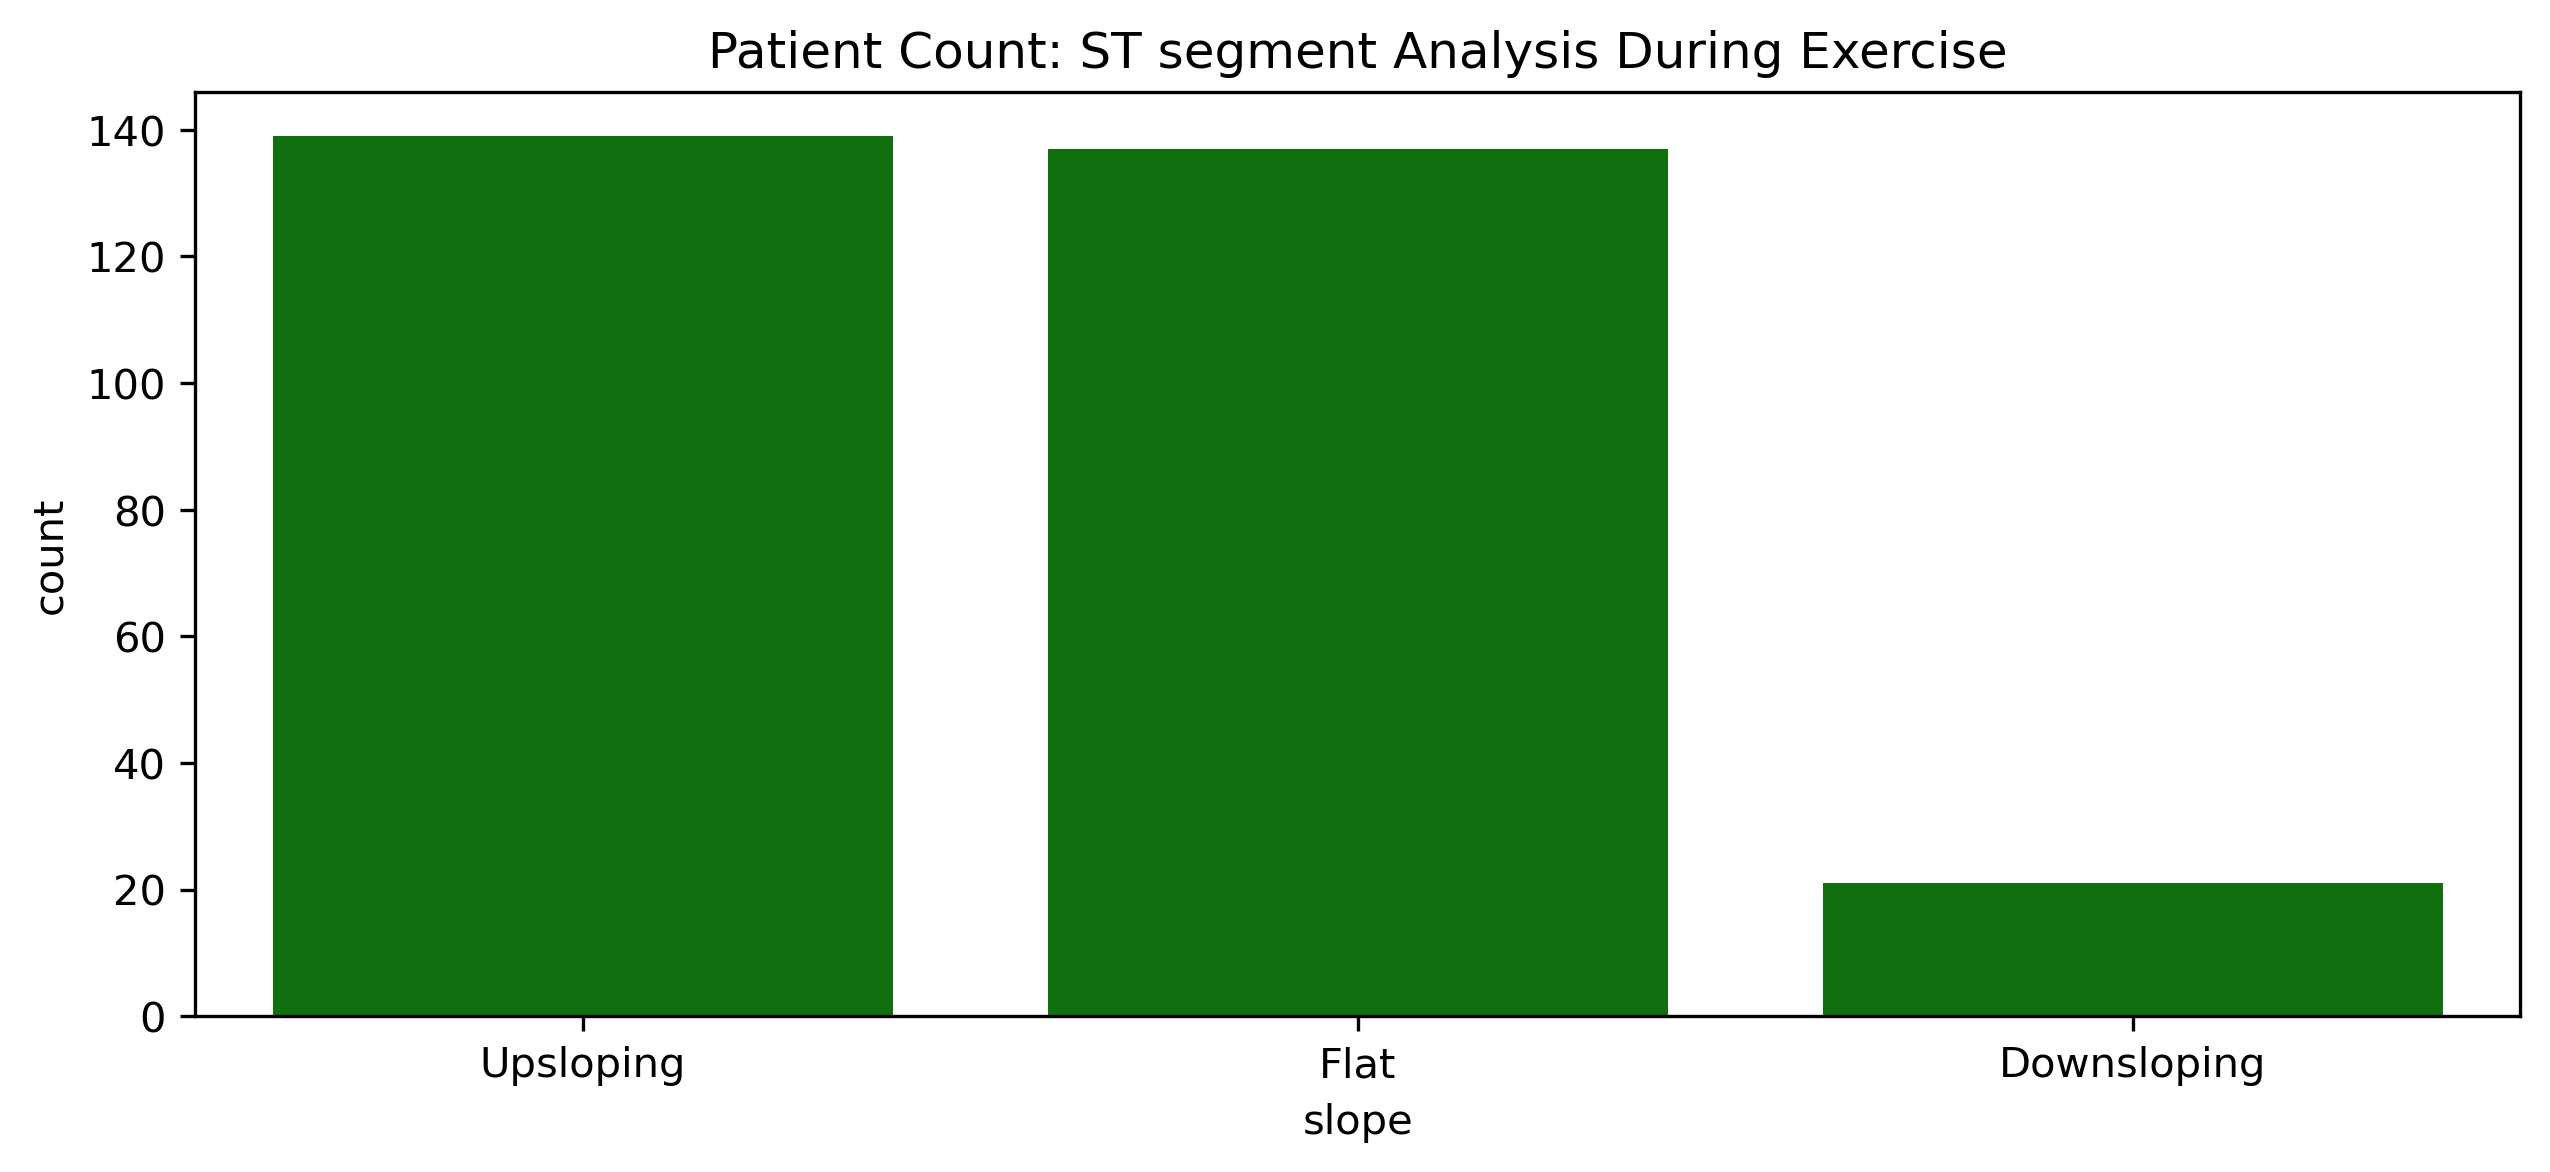

In [31]:
#Slope Analysis (ST segment Analysis During Exercise)

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'slope', color = 'green')

#Define labels
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Upsloping', 'Flat', 'Downsloping'])
plt.title('Patient Count: ST segment Analysis During Exercise')

plt.show()

**Comments:**
* The plot shows an equal distribution between patients with an Upsloping ECG segment and a Flat ECG segment. Upsloping ST segments are typically considered normal, whereas a flat ECG segment can be a sign of myocardial ischemia where the heart muscle is not getting enough oxygen-rich blood during exertion.
* However, there is a small proportion of patients with downsloping. This suggests more severe ischaemia in comparison to a flat ST-T wave and is often associated with extensive/multvessel coronary blockages.

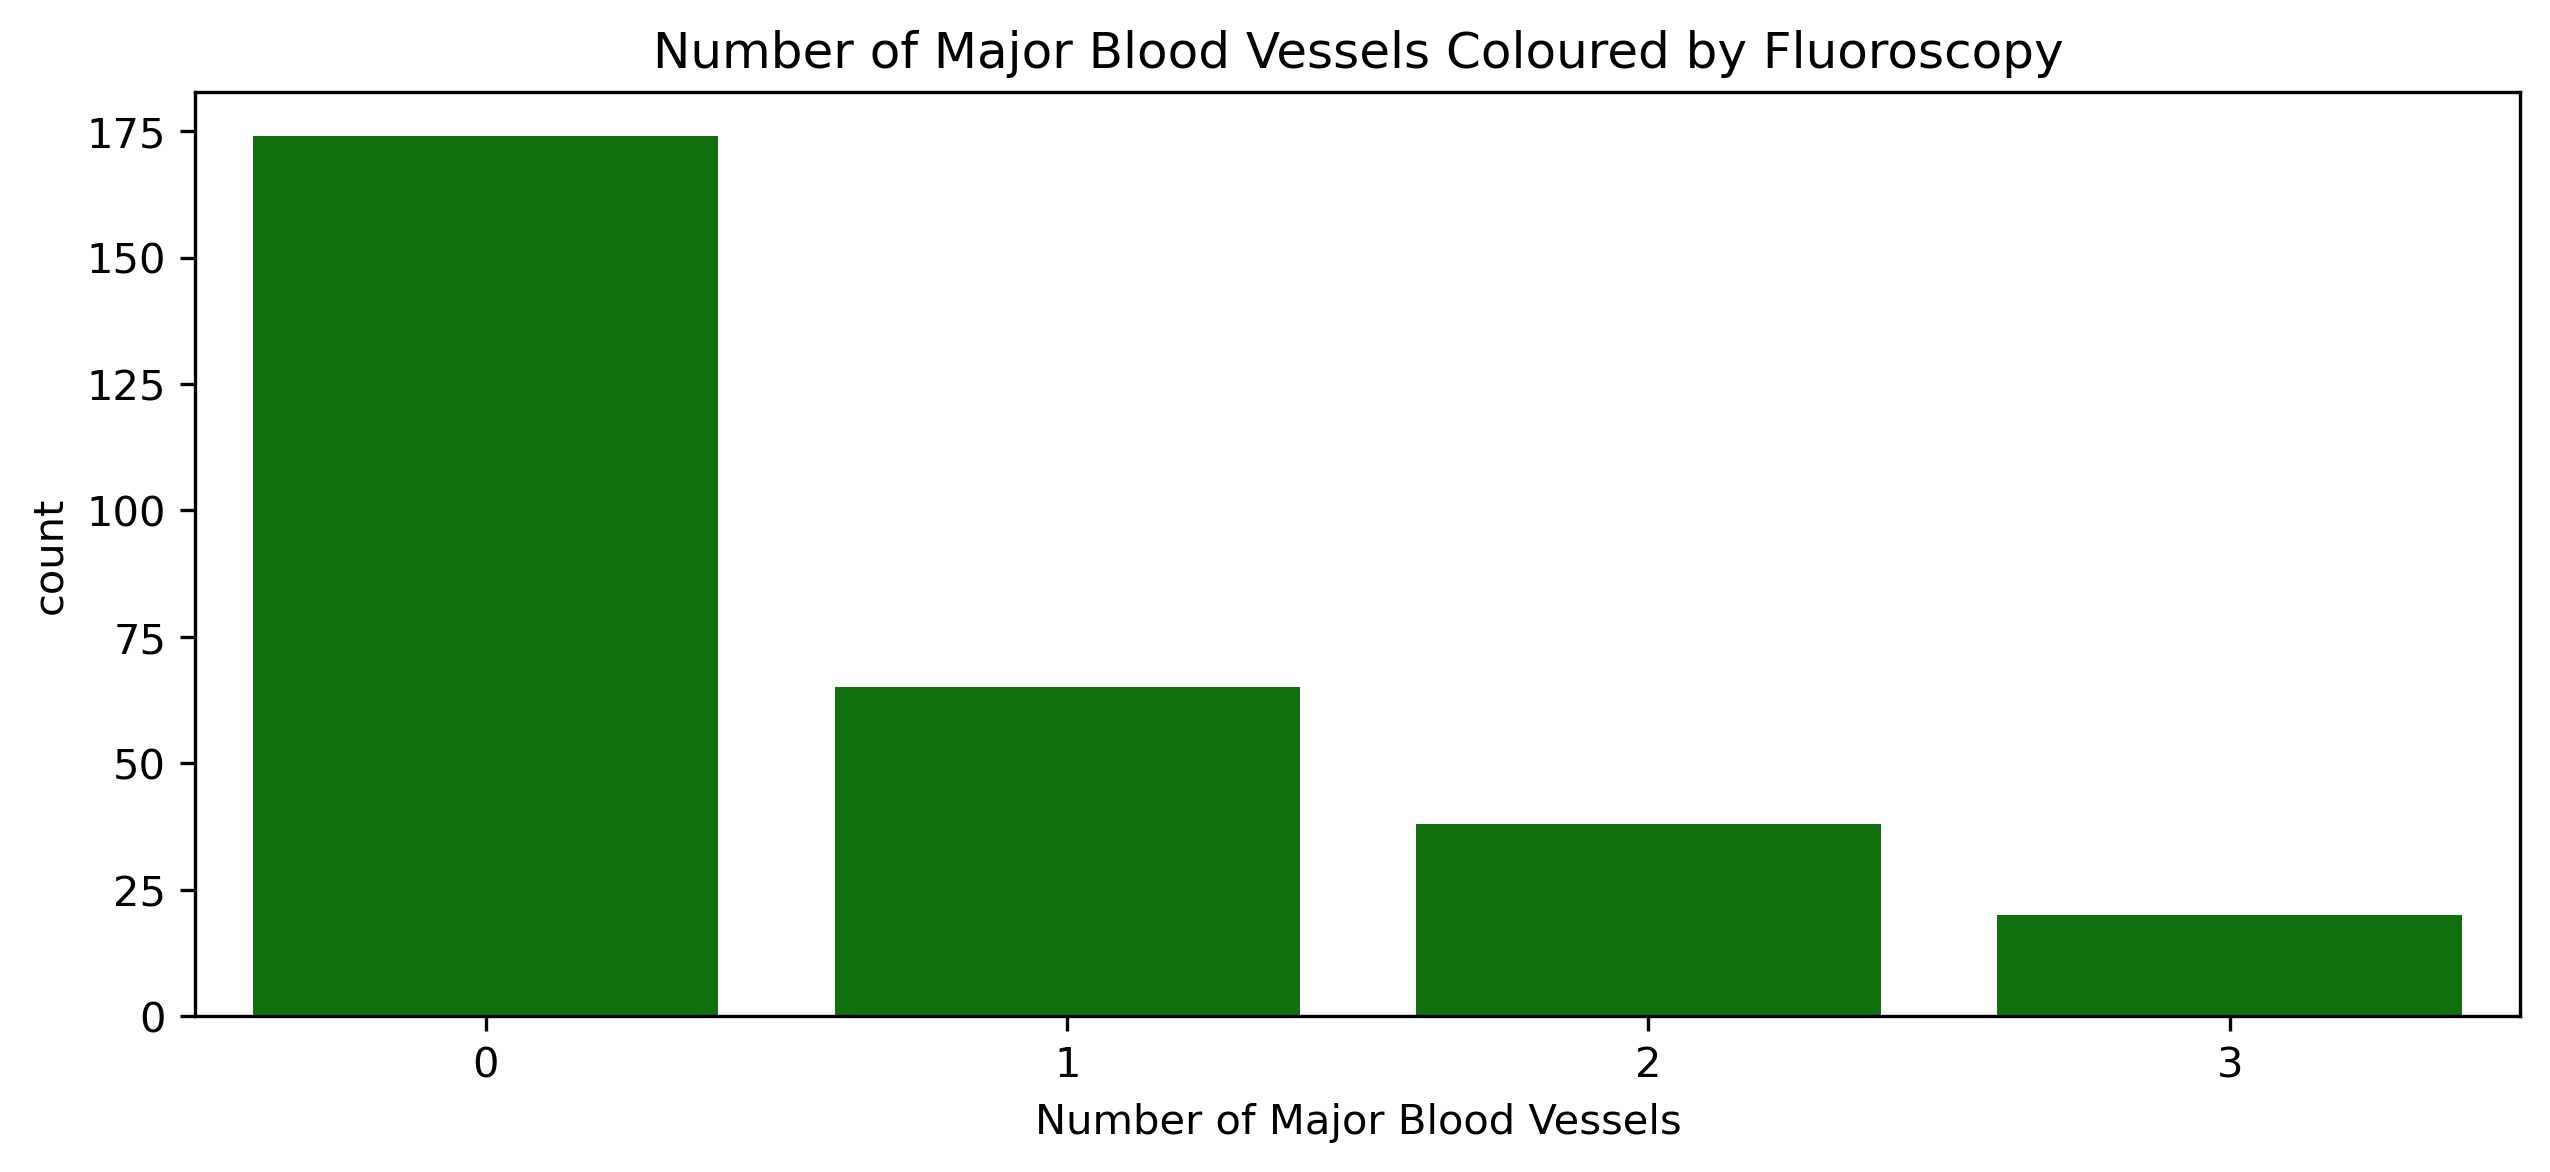

In [32]:
#ca Analysis - Number of major blood cessels coloured by fluoroscopy

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'ca', color = 'green')

#Define labels
plt.xlabel('Number of Major Blood Vessels')
plt.title('Number of Major Blood Vessels Coloured by Fluoroscopy')

plt.show()

**Comments:**
* The graph shows that a large proportion of patients did not have any major blood vessels (RCA, LAD, LCX) coloured by Fluoroscopy, suggesting that there is no significant narrowing of major epicardial coronary arteries. This could be due to the patients not having CAD or CAD has been induced by microvascular blockages which is missed by fluoroscopy.
* Very few patients seem to have blockages in all three major blood vessels, with more patients having a blockage in one or two major blood vessels. This is as expected as triple-vessel disease is much less common and associated with more severe CAD.

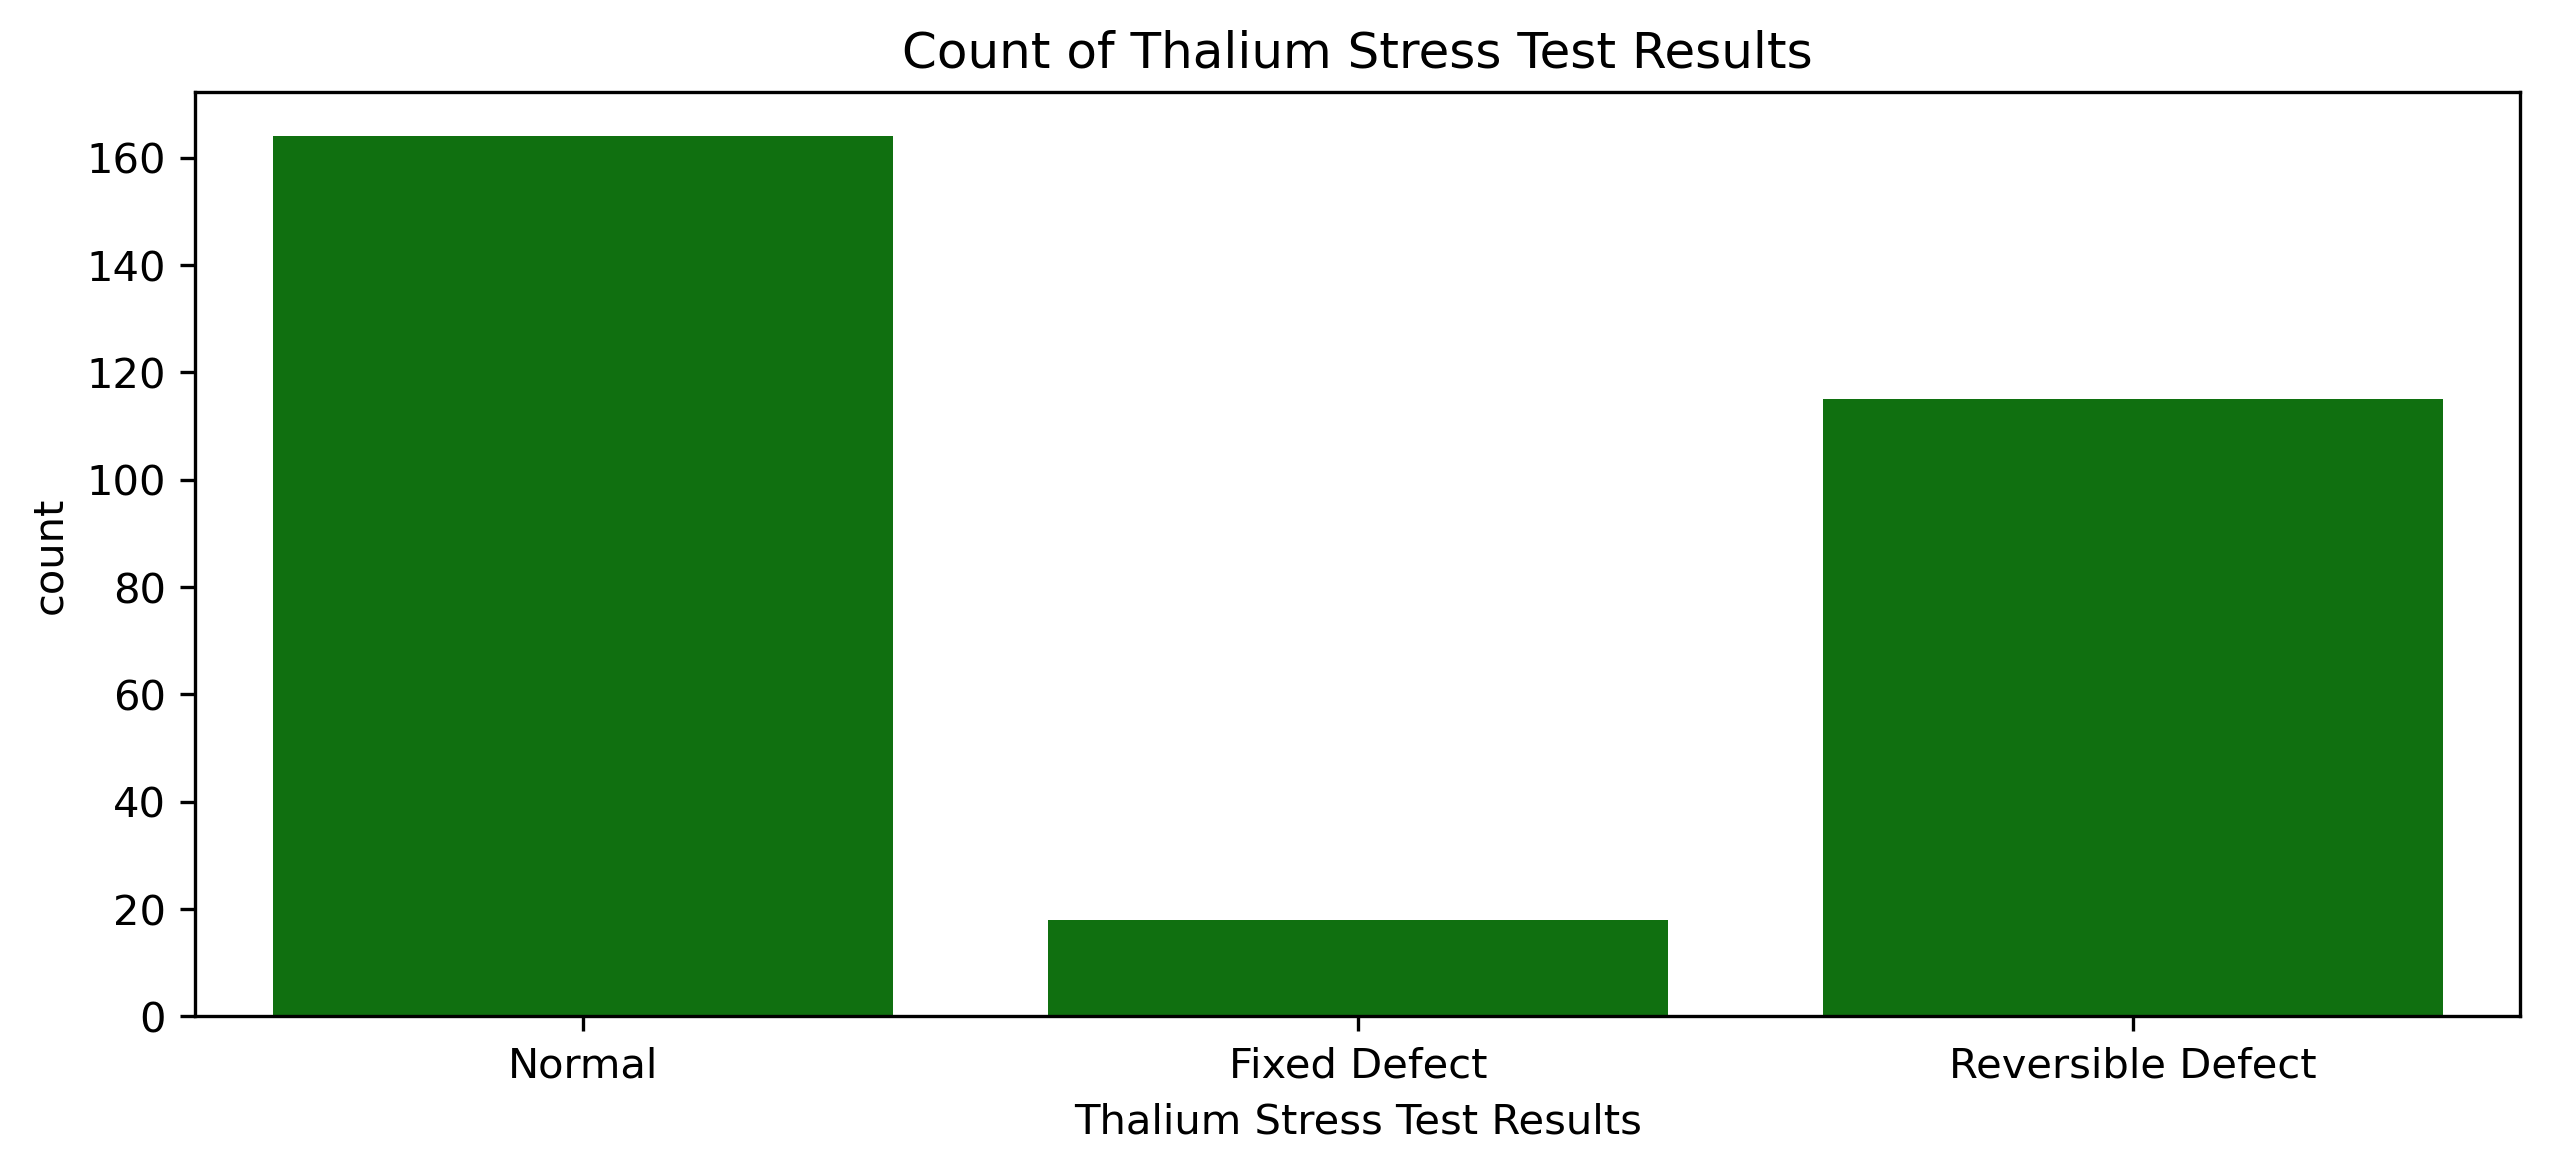

In [33]:
## Thal Analysis (Thalium Stress Test Resul)

#Plot figure
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df, x = 'thal', color = 'green')

#Define labels
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Normal', 'Fixed Defect', 'Reversible Defect'])
plt.xlabel('Thalium Stress Test Results')
plt.title('Count of Thalium Stress Test Results')

plt.show()

**Comments:**
* The graph shows that a large proportion of patients had a normal thallium stress test result, meaning blood flow to the heart muscle was adequate during both stress and rest.
* The graph also shows that majority of patients showed a reversible defect where blood is reduced during the stress phase but is normal during rest. This indicates inducible ischemia, where a coronary artery is partially blocked.
* There is a small minority with a fixed defect, which means a specific area of the heart shows reduced thallium uptake - however, it is less common than a reversible defect and is often associated with permanent damage (e.g. infarction), which is not always present in all CAD patients. This explains why it makes up a minority of the dataset.

## Target Analysis

Text(0.5, 1.0, 'Class Imbalance: Count of CAD Diagnosis')

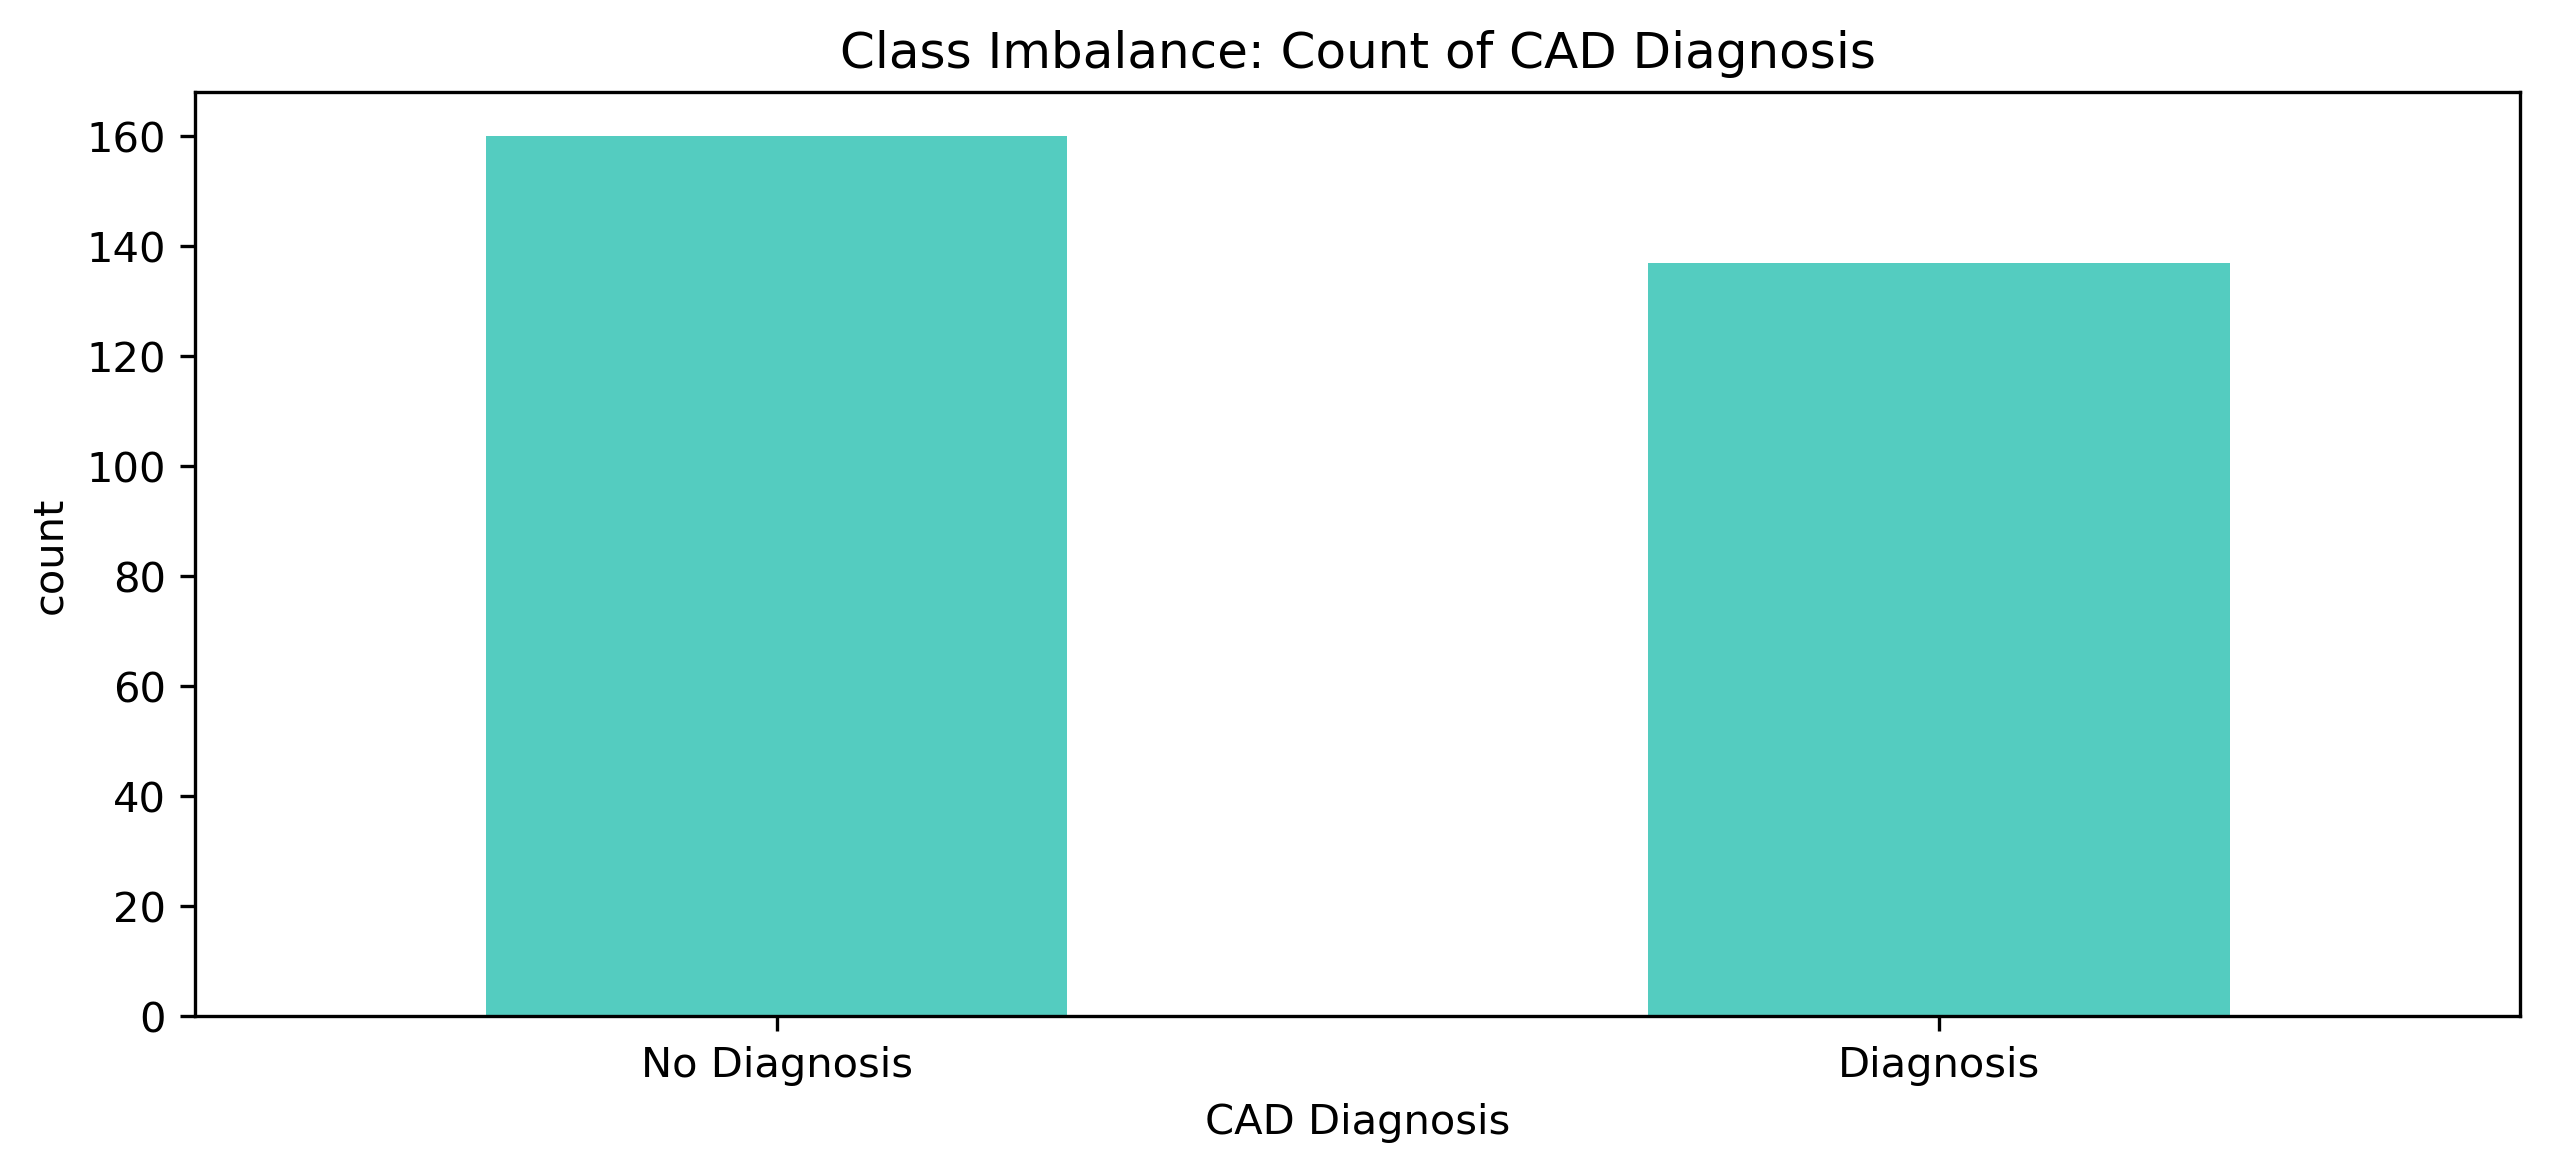

In [34]:
#Check for Class Imbalance

#Copy DataFrame and replace values 1-4 with 1 so end up with 2 categories: 'no diagnosis' and 'diagnosis'
df_class = df.copy()
df_class['target'] = df_class['target'].replace({1:1, 2:1, 3:1, 4:1})

#Plot graph
plt.figure(figsize = (10,4), dpi = 300)
ax = sns.countplot(data = df_class, x = 'target', width = 0.5, color = 'turquoise')

#Define Labels
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Diagnosis', 'Diagnosis'])
plt.xlabel('CAD Diagnosis')
plt.title('Class Imbalance: Count of CAD Diagnosis')

In [35]:
#Class Imbalance Ratio
counts = df_class['target'].value_counts()
max_count = counts.max()
min_count = counts.min()

imbalance_ratio = max_count/min_count
print(f'Majority Class Count: {max_count}')
print(f'Minority Class Count: {min_count}')
print(f'Imbalance Ratio: {imbalance_ratio:.2f}:1')

Majority Class Count: 160
Minority Class Count: 137
Imbalance Ratio: 1.17:1


**Comments:**
* The plot shows that there is an imbalance between both classes that form the target variable.
* Therefore, class imbalancing will need to be dealt with appropriately during preprocessing as it could introduce bias into the models, disrupt evaluation metric results and lead to inaccurate predictive values.

In [36]:
#Numerical Variables vs Target Variable

#Point Biserial Correlation Analysis

#Define list of numerical columns
num_cols = ['age','trestbps','chol','thalach','oldpeak']

#Loop through each numerical column and print name of column and the point-biserial correlation between numerical vs binary column
for col in num_cols:
    print(col, pointbiserialr(df_class[col], df_class['target']))

age SignificanceResult(statistic=0.22707515465323652, pvalue=7.862867945608163e-05)
trestbps SignificanceResult(statistic=0.15349002570252018, pvalue=0.008054796358874853)
chol SignificanceResult(statistic=0.08028475098000232, pvalue=0.16758776714742252)
thalach SignificanceResult(statistic=-0.4238170641833712, pvalue=2.2397153233937345e-14)
oldpeak SignificanceResult(statistic=0.4240520567159989, pvalue=2.1597372771142323e-14)


Text(0.5, 1.0, 'Correlation analysis: Numeric Features vs Target Variables')

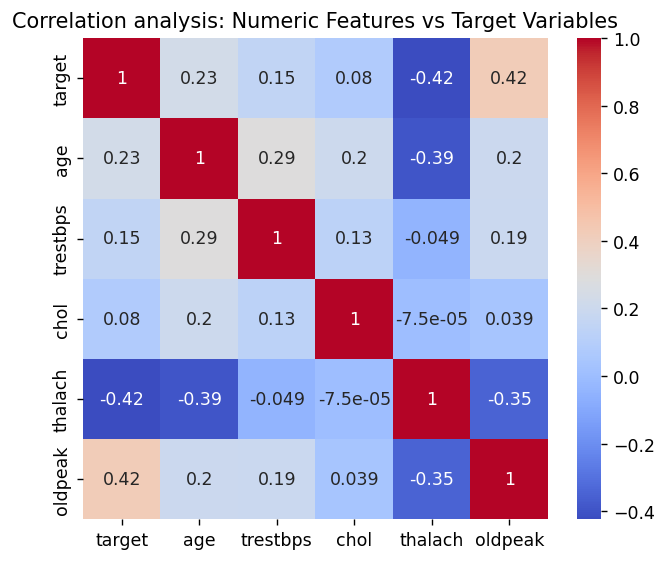

In [37]:
#Visualise Correlations with Heatmap

#Select the target and numerical variables and calculate the correlations between them
corr = df_class[['target']+num_cols].corr()

#Visualise the correlations calculated as a heatmap
plt.figure(figsize = (6,5), dpi = 125)
sns.heatmap(corr, annot = True, cmap = 'coolwarm')

#Define title
plt.title('Correlation analysis: Numeric Features vs Target Variables')

**Comments:**
* From the point biserial correlation results, we see that there are 4 numerical columns that have a statistically significant correlation (p < 0.05) with the target variable. These columns are: `age` (p = 7.86e-05), `trestbps` (p = 0.008), `thalach` (p = 2.24e-14), and `oldpeak` (p = 2.16e-14). Cholesterol does not show a significant correlation.
* From these columns, we see that `oldpeak` has the strongest positive correlation with the target variable, with a correlation coefficient of 0.42. This suggests that as the mm of ST depression increase, so does the incidence of CAD. This aligns with the guidlines provided by NICE (described above).
* Furthermore, we see that `thalach` has the strongest negative correlation with the target variable, with a correlation coefficient of -0.42. This suggests that as max heart rate achieved during exercise decreases, the incidence of CAD diagnosis increases. This is to be expected as was described above.

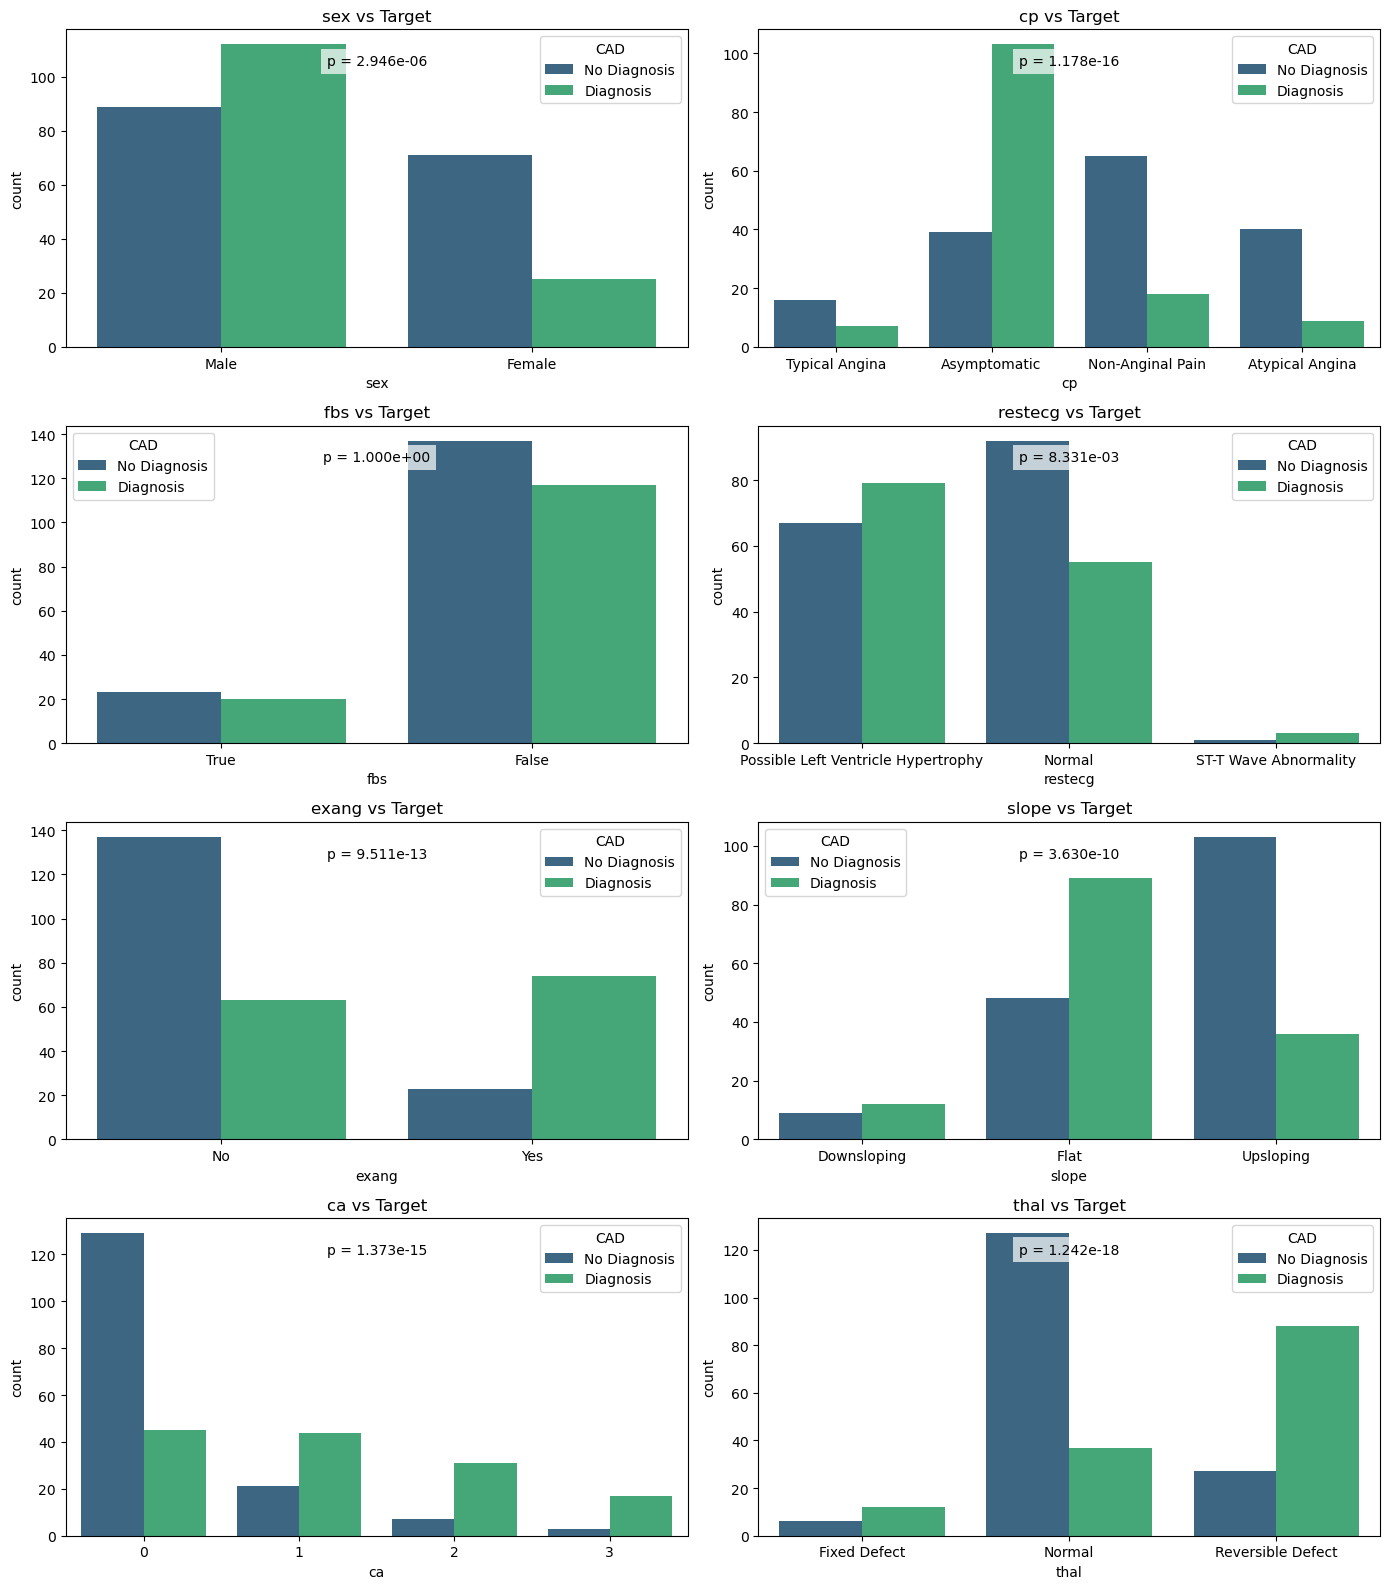

In [38]:
## Categorical Features vs Target Variable

#Rename Categories (with names not encoding)
df_class['sex'] = df_class['sex'].replace({0: 'Female', 1: 'Male'})

df_class['cp'] = df_class['cp'].replace({
    1: 'Typical Angina',
    2: 'Atypical Angina',
    3: 'Non-Anginal Pain',
    4: 'Asymptomatic'
})

df_class['fbs'] = df_class['fbs'].replace({
    0: 'False',
    1: 'True'
})

df_class['restecg'] = df_class['restecg'].replace({
    0: 'Normal',
    1: 'ST-T Wave Abnormality', 
    2: 'Possible Left Ventricle Hypertrophy'
})

df_class['exang'] = df_class['exang'].replace({
    0: 'No',
    1: 'Yes', 
})

df_class['slope'] = df_class['slope'].replace({
    1: 'Upsloping', 
    2: 'Flat', 
    3: 'Downsloping'
})


df_class['thal'] = df_class['thal'].replace({
    3: 'Normal', 
    6: 'Fixed Defect', 
    7: 'Reversible Defect'
})

df_class['target'] = df_class['target'].replace({
    0: 'No Diagnosis',
    1: 'Diagnosis'
})

#Plot graph
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope','ca','thal']

#Create a 4x2 grid of subplots
fig, axes = plt.subplots(nrows = 4, ncols = 2, figsize = (14,16))
axes = axes.flatten() #converts 2D array of axes into simple list to loop through

#Loop through each categorical variable and draw a countplot - zip = one subplot -> one category
for ax, col in zip(axes, cat_cols):
    #hue = target - splits each bar into diagnosis vs no diagnosis
    #ax = ax - makes sure each plot goes into the correct subplot
    sns.countplot(data = df_class, x= col, hue = 'target', ax = ax, palette = 'viridis')
    ax.set_title(f'{col} vs Target')
    ax.legend(title = 'CAD')

    #Chi-square test - tests whether the distribution of categories is significantly different between Diagnosis vs No Diagnosis
    #pd.crosstab to create a contingency table/stats.chi2_contingency() = chi-square test of independence
    contingency = pd.crosstab(df_class[col], df_class['target'])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)

    #Annotate p-value on the plot
    #0.5, 0.9 = position inside subplot| p:.3e = scientific notion
    ax.text(0.5, 0.9, f'p = {p:.3e}', transform = ax.transAxes,
            ha = 'center', va = 'center', fontsize = 10, color = 'black',
            bbox = dict(facecolor = 'white', alpha = 0.7, edgecolor = 'none'))

plt.tight_layout()
plt.show()

**Comments:**
* The bar charts show that 7 categorical features have a statistically significant (p < 0.05) difference between a diagnosis of CAD and no diagnosis of CAD: `sex`, `cp`, `restecg`, `exang`, `slope`, `ca`, and `thal`.
* Fasting blood sugar (`fbs`) is the only categorical feature showing no statistical difference (p = 1.00).
* The countplots illustrate how the distribution of categories differs between CAD and non‑CAD patients. For example:
    * Chest pain type (`cp`): Patients with CAD are overwhelmingly in the asymptomatic category, whereas
non‑CAD patients show more typical or atypical angina.
    * `Slope`: CAD patients most commonly show a flat slope during exercise ECG, consistent with ischemic changes.
    * Resting ECG (`restecg`): CAD patients show more ST‑T wave abnormalities or possible LV hypertrophy, while non‑CAD patients are more likely to have a normal resting ECG.
    * Exercise‑induced angina (`exang`): CAD patients are far more likely to experience angina during exercise.
    * Number of major vessels (`ca`): CAD patients tend to have more vessels coloured by fluoroscopy, reflecting greater disease burden.
    * Thalassemia test (`thal`): CAD patients show more fixed or reversible defects, while non‑CAD patients more often have normal thal results.

## Summary
* The dataset shows a class imbalance in the target variable, with more individuals not diagnosed with CAD. This imbalance may influence model performance and will require attention during modelling (e.g., resampling or class‑weighted algorithms).

* Among numerical features, oldpeak (ST depression) and thalach (maximum heart rate achieved) show the strongest associations with CAD. Oldpeak is positively correlated with CAD, while thalach is negatively correlated, both aligning with clinical expectations.

* Age and resting blood pressure show weaker but statistically significant relationships with CAD. Cholesterol shows no meaningful univariate association.

* Seven categorical variables show statistically significant differences between CAD and non‑CAD groups:
sex, chest pain type (cp), resting ECG (restecg), exercise‑induced angina (exang), slope, number of major vessels (ca), and thal.

* Fasting blood sugar (fbs) is the only categorical variable with no statistical difference between groups (p = 1.00).

* CAD patients are more likely to present with asymptomatic chest pain, flat ST slopes, exercise‑induced angina, abnormal ECG findings, and multiple affected vessels.

* Overall, the dataset contains several clinically meaningful predictors of CAD, providing a strong foundation for feature engineering and model development.